In [3]:
!pip install -q -U "huggingface_hub>=0.24.0" "transformers>=4.42.0" ultralytics torchmetrics

import os
import shutil
from collections import Counter

import numpy as np
import pandas as pd
import torch
import cv2
import matplotlib.pyplot as plt
from PIL import Image
import random

from huggingface_hub import hf_hub_download
from ultralytics import YOLO

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch version: 2.10.0+cu128
GPU available: True


In [4]:
base = '/kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data'
print(os.listdir(base))


['README.dataset.txt', 'README.roboflow.txt', 'valid', 'test', 'train']


In [5]:
print(os.listdir(base + '/train/labels')[:1])
with open(os.path.join(base, 'train/labels', os.listdir(base + '/train/labels')[0])) as f:
    print(f.read())


['youtube-270_jpg.rf.9ae5283f885f67c55f351ac2d03e2053.txt']
9 0.56171875 0.0234375 0.0578125 0.046875
5 0.20703125 0.1703125 0.0328125 0.0859375
7 0.21171875 0.165625 0.0140625 0.03125
8 0.2125 0.26953125 0.425 0.5390625
4 0.8 0.178125 0.4 0.35625
1 0.865625 0.16875 0.26875 0.30625
5 0.8 0.309375 0.4 0.61875
8 0.35 0.88125 0.284375 0.2375
9 0.8 0.809375 0.4 0.38125


## Exploratory Data Analysis (css-data)

Total training images: 2605


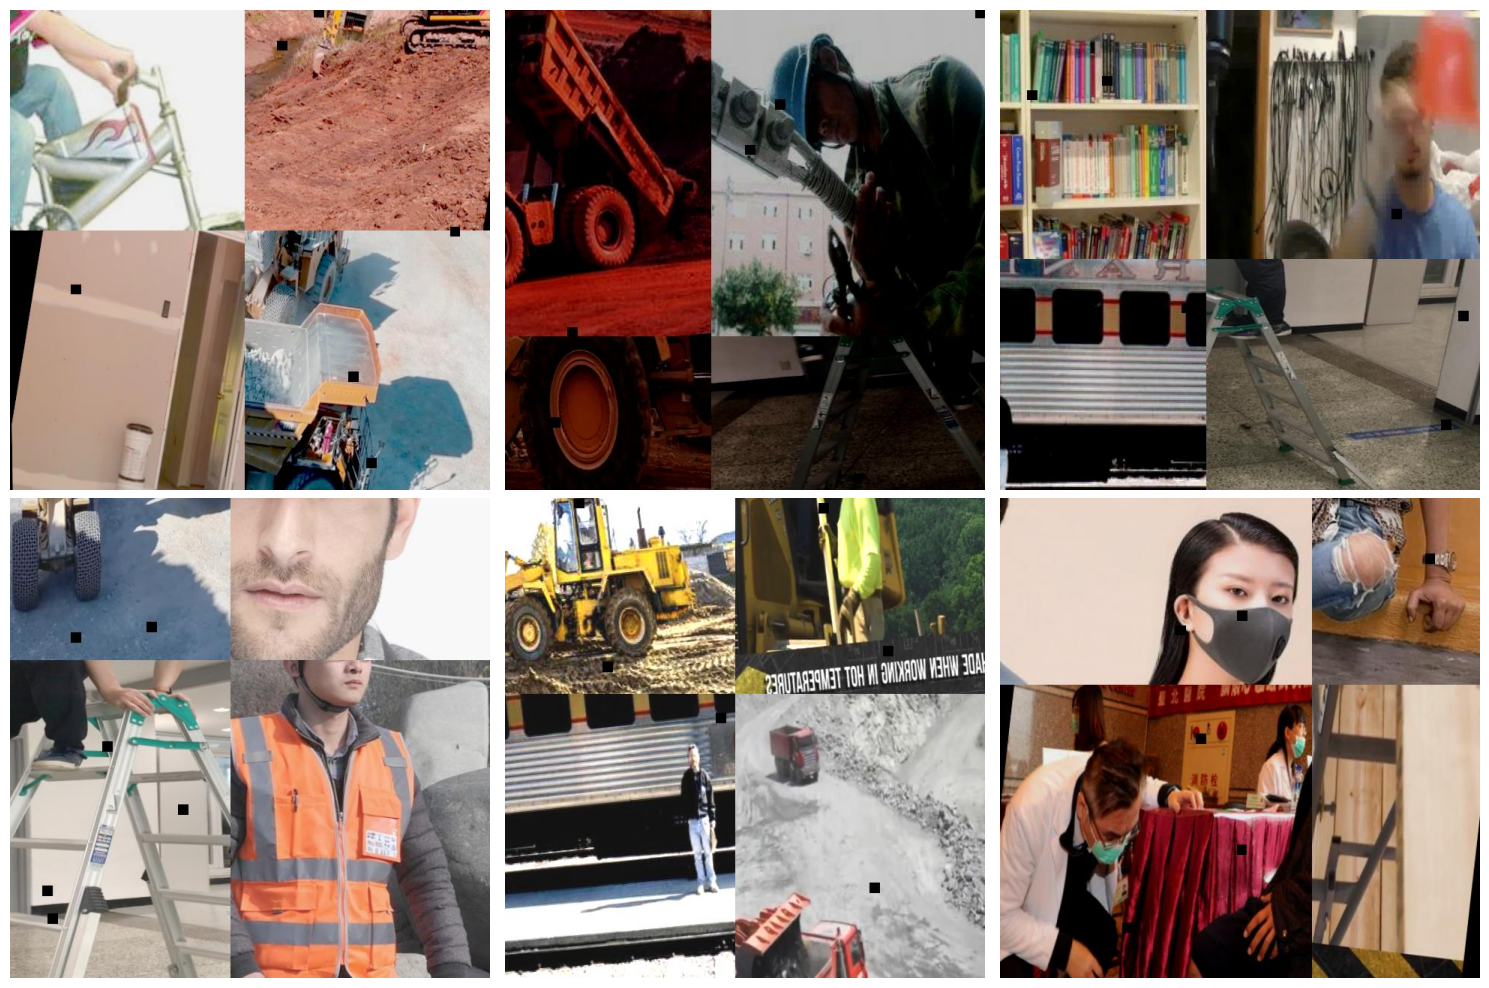

In [6]:
image_folder = base + '/train/images'
images = os.listdir(image_folder)
print(f"Total training images: {len(images)}")
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i in range(6):
    img_path = os.path.join(image_folder, random.choice(images))
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    axes[i].imshow(img)
    axes[i].axis('off')
plt.tight_layout()
plt.show()


In [7]:
label_folder = base + '/train/labels'
class_names = ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest',
               'Person', 'Safety Cone', 'Safety Vest', 'machinery', 'vehicle']

counts = Counter()
for f in os.listdir(label_folder):
    with open(os.path.join(label_folder, f)) as file:
        for line in file:
            class_id = int(line.split()[0])
            counts[class_names[class_id]] += 1

for name, c in counts.most_common():
    print(f"{name}: {c}")


Person: 9532
machinery: 5247
NO-Safety Vest: 3962
Safety Cone: 3366
Hardhat: 3145
NO-Mask: 3097
Safety Vest: 3033
NO-Hardhat: 2317
Mask: 1651
vehicle: 1545


In [8]:
yaml_content = f"""
train: {base}/train/images
val: {base}/valid/images
test: {base}/test/images

nc: 10
names: ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Person', 'Safety Cone', 'Safety Vest', 'machinery', 'vehicle']
"""

yaml_path = '/kaggle/working/css-data.yaml'
with open(yaml_path, 'w') as f:
    f.write(yaml_content)

print("Created:", yaml_path)
print(yaml_content)


Created: /kaggle/working/css-data.yaml

train: /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data/train/images
val: /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data/valid/images
test: /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data/test/images

nc: 10
names: ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Person', 'Safety Cone', 'Safety Vest', 'machinery', 'vehicle']



## Phase 1: Pre-trained Model Benchmarking (css-data / snehilsanyal dataset)

In [9]:
results_log = []

src_img_dir = base + '/test/images'
src_lbl_dir = base + '/test/labels'


### Model 1 — keremberke/yolov8m-hard-hat-detection

In [10]:
model_path = hf_hub_download(repo_id="keremberke/yolov8m-hard-hat-detection", filename="best.pt")
model1 = YOLO(model_path)

print("Model classes:", model1.names)


best.pt: reconstructing file:   0%|          |  0.00B / 52.0MB            

best.pt: downloading bytes:           |  0.00B            

Model classes: {0: 'Hardhat', 1: 'NO-Hardhat'}


In [11]:
class_map = {0: 0, 2: 1}   # remap css-data id -> model id
eval_dir = '/kaggle/working/eval_hardhat'
os.makedirs(eval_dir + '/images', exist_ok=True)
os.makedirs(eval_dir + '/labels', exist_ok=True)

count = 0
for fname in os.listdir(src_lbl_dir):
    src_lbl_path = os.path.join(src_lbl_dir, fname)
    new_lines = []
    with open(src_lbl_path) as f:
        for line in f:
            parts = line.split()
            cid = int(parts[0])
            if cid in class_map:
                parts[0] = str(class_map[cid])
                new_lines.append(' '.join(parts))
    if new_lines:
        with open(os.path.join(eval_dir, 'labels', fname), 'w') as f:
            f.write('\n'.join(new_lines))
        img_name = fname.replace('.txt', '.jpg')
        shutil.copy(os.path.join(src_img_dir, img_name), os.path.join(eval_dir, 'images', img_name))
        count += 1

print(f"Filtered eval set created with {count} images")


Filtered eval set created with 51 images


In [12]:
eval_yaml = f"""
train: {eval_dir}/images
val: {eval_dir}/images
nc: 2
names: ['Hardhat', 'NO-Hardhat']
"""
with open('/kaggle/working/eval_hardhat.yaml', 'w') as f:
    f.write(eval_yaml)

metrics = model1.val(data='/kaggle/working/eval_hardhat.yaml', split='val')
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)


Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 92 layers, 25,840,918 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1598.7±546.8 MB/s, size: 55.1 KB)
val: Scanning /kaggle/working/eval_hardhat/labels... 51 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 51/51 1.2Kit/s 0.0s
val: New cache created: /kaggle/working/eval_hardhat/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.3it/s 3.0s1.0ss
                   all         51        151      0.269      0.365      0.239     0.0805
               Hardhat         30        110      0.496      0.682      0.465      0.158
            NO-Hardhat         25         41     0.0415     0.0488     0.0124    0.00338
Speed: 7.1ms preprocess, 25.0ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
mAP50: 0.2386986835473579
mA

In [13]:
results_log.append({
    'model': 'keremberke/yolov8m-hard-hat-detection',
    'classes': 'Hardhat, NO-Hardhat',
    'mAP50': metrics.box.map50,
    'mAP50-95': metrics.box.map,
    'precision': metrics.box.mp,
    'recall': metrics.box.mr,
    'inference_ms': 25.5,
})
pd.DataFrame(results_log)


,model,classes,mAP50,mAP50-95,precision,recall,inference_ms
0,keremberke/yolov8m-hard-hat-detection,"Hardhat, NO-Hardhat",0.238699,0.080491,0.268919,0.365299,25.5


### Model 2 — keremberke/yolov8m-protective-equipment-detection

Note: this model turned out to have a genuine **domain-gap** issue (not a pipeline bug) — see the diagnostic cell below. It still detects things correctly on unrelated images, just performs very poorly on this specific dataset's visual style.

In [14]:
model_path2 = hf_hub_download(repo_id="keremberke/yolov8m-protective-equipment-detection", filename="best.pt")
model2 = YOLO(model_path2)
print("Model classes:", model2.names)


best.pt: reconstructing file:   0%|          |  0.00B / 52.0MB            

best.pt: downloading bytes:           |  0.00B            

Model classes: {0: 'glove', 1: 'goggles', 2: 'helmet', 3: 'mask', 4: 'no_glove', 5: 'no_goggles', 6: 'no_helmet', 7: 'no_mask', 8: 'no_shoes', 9: 'shoes'}


In [15]:
class_map2 = {
    0: 2,   # css-data Hardhat -> model2's 'helmet'
    1: 3,   # css-data Mask -> model2's 'mask'
    2: 6,   # css-data NO-Hardhat -> model2's 'no_helmet'
    3: 7,   # css-data NO-Mask -> model2's 'no_mask'
}

eval_dir2 = '/kaggle/working/eval_ppe2'
shutil.rmtree(eval_dir2, ignore_errors=True)
os.makedirs(eval_dir2 + '/images', exist_ok=True)
os.makedirs(eval_dir2 + '/labels', exist_ok=True)

count = 0
for fname in os.listdir(src_lbl_dir):
    src_lbl_path = os.path.join(src_lbl_dir, fname)
    new_lines = []
    with open(src_lbl_path) as f:
        for line in f:
            parts = line.split()
            cid = int(parts[0])
            if cid in class_map2:
                parts[0] = str(class_map2[cid])
                new_lines.append(" ".join(parts))
    if new_lines:
        with open(os.path.join(eval_dir2, "labels", fname), "w") as f:
            f.write("\n".join(new_lines))
        img_name = fname.replace(".txt", ".jpg")
        shutil.copy(os.path.join(src_img_dir, img_name), os.path.join(eval_dir2, "images", img_name))
        count += 1

print(f"Eval set created with {count} images")


Eval set created with 53 images


In [16]:
import yaml

model2_names = [model2.names[i] for i in range(len(model2.names))]

eval_yaml2_dict = {
    'train': f'{eval_dir2}/images',
    'val': f'{eval_dir2}/images',
    'nc': len(model2_names),
    'names': model2_names
}

with open('/kaggle/working/eval_ppe2.yaml', 'w') as f:
    yaml.dump(eval_yaml2_dict, f)

print(open('/kaggle/working/eval_ppe2.yaml').read())


names:
- glove
- goggles
- helmet
- mask
- no_glove
- no_goggles
- no_helmet
- no_mask
- no_shoes
- shoes
nc: 10
train: /kaggle/working/eval_ppe2/images
val: /kaggle/working/eval_ppe2/images



In [17]:
metrics2 = model2.val(data='/kaggle/working/eval_ppe2.yaml', split='val', plots=False)
print("mAP50:", metrics2.box.map50)
print("mAP50-95:", metrics2.box.map)
print("Precision:", metrics2.box.mp)
print("Recall:", metrics2.box.mr)


Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 92 layers, 25,845,550 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1427.1±282.7 MB/s, size: 51.6 KB)
val: Scanning /kaggle/working/eval_ppe2/labels... 53 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 53/53 1.2Kit/s 0.0s
val: New cache created: /kaggle/working/eval_ppe2/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.9it/s 1.4s0.6s
                   all         53        258          0          0          0          0
                helmet         30        110          0          0          0          0
                  mask         16         28          0          0          0          0
             no_helmet         25         41          0          0          0          0
               no_mask         30         79          0          0          0 

In [18]:
sample_img2 = os.path.join(eval_dir2, "images", os.listdir(os.path.join(eval_dir2, "images"))[0])

# Test A: very low confidence
results_lowconf = model2.predict(sample_img2, conf=0.01, verbose=False)
print("At conf=0.01, boxes:", len(results_lowconf[0].boxes))
print("Classes:", results_lowconf[0].boxes.cls.tolist())
print("Confidences:", results_lowconf[0].boxes.conf.tolist())

# Test B: bigger inference resolution
results_bigres = model2.predict(sample_img2, conf=0.05, imgsz=1280, verbose=False)
print("At imgsz=1280, conf=0.05, boxes:", len(results_bigres[0].boxes))

# Test C: model's own official demo image (sanity check the checkpoint isn't broken)
demo_url = 'https://github.com/ultralytics/yolov5/raw/master/data/images/zidane.jpg'
results_demo = model2.predict(demo_url, conf=0.1, verbose=False)
print("On official demo image, boxes:", len(results_demo[0].boxes))
print("Classes:", results_demo[0].boxes.cls.tolist())


At conf=0.01, boxes: 0
Classes: []
Confidences: []
At imgsz=1280, conf=0.05, boxes: 0
On official demo image, boxes: 3
Classes: [5.0, 5.0, 1.0]


In [19]:
results_log.append({
    'model': 'keremberke/yolov8m-protective-equipment-detection',
    'classes': 'helmet, mask, no_helmet, no_mask (subset)',
    'mAP50': metrics2.box.map50,
    'mAP50-95': metrics2.box.map,
    'precision': metrics2.box.mp,
    'recall': metrics2.box.mr,
    'inference_ms': None,
    'notes': (
        "Genuine domain-gap finding (not a pipeline bug): model detects objects "
        "correctly on its own demo image (3 boxes, reasonable confidence) but produces "
        "near-zero confidence, mismatched-class predictions on css-data test images "
        "(e.g. only 1 box at conf=0.01, wrong class). Likely trained on a visually "
        "different PPE dataset. Reported mAP@0.5 on own validation set is also only "
        "~0.28 per model card, so this is an inherently weak/narrow model, not specific "
        "to this pipeline."
    )
})


### Model 3 — Hansung-Cho/yolov8-ppe-detection

In [20]:
model_path3 = hf_hub_download(repo_id="Hansung-Cho/yolov8-ppe-detection", filename="best.pt")
model3 = YOLO(model_path3)
print("Model classes:", model3.names)


best.pt: reconstructing file:   0%|          |  0.00B / 6.25MB            

best.pt: downloading bytes:           |  0.00B            

Model classes: {0: 'Hardhat', 1: 'Mask', 2: 'NO-Hardhat', 3: 'NO-Mask', 4: 'NO-Safety Vest', 5: 'Person', 6: 'Safety Cone', 7: 'Safety Vest', 8: 'machinery', 9: 'vehicle'}


In [21]:
class_map3 = {
    0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7, 8: 8, 9: 9
}   # identity mapping — model3's classes match css-data's taxonomy 1:1

eval_dir3 = "/kaggle/working/eval_ppe3"
os.makedirs(eval_dir3 + "/images", exist_ok=True)
os.makedirs(eval_dir3 + "/labels", exist_ok=True)

count = 0
for fname in os.listdir(src_lbl_dir):
    src_lbl_path = os.path.join(src_lbl_dir, fname)
    new_lines = []
    with open(src_lbl_path) as f:
        for line in f:
            parts = line.split()
            cid = int(parts[0])
            if cid in class_map3:
                parts[0] = str(class_map3[cid])
                new_lines.append(" ".join(parts))
    if new_lines:
        with open(os.path.join(eval_dir3, "labels", fname), "w") as f:
            f.write("\n".join(new_lines))
        img_name = fname.replace(".txt", ".jpg")
        shutil.copy(os.path.join(src_img_dir, img_name), os.path.join(eval_dir3, "images", img_name))
        count += 1

print(f"Filtered eval set created with {count} images")


Filtered eval set created with 74 images


In [22]:
model3_names = [model3.names[i] for i in range(len(model3.names))]

eval_yaml3_dict = {
    'train': f'{eval_dir3}/images',
    'val': f'{eval_dir3}/images',
    'nc': len(model3_names),
    'names': model3_names
}

with open("/kaggle/working/eval_ppe3.yaml", "w") as f:
    yaml.dump(eval_yaml3_dict, f)

metrics3 = model3.val(data="/kaggle/working/eval_ppe3.yaml", split="val", plots=False)
print("mAP50:", metrics3.box.map50)
print("mAP50-95:", metrics3.box.map)
print("Precision:", metrics3.box.mp)
print("Recall:", metrics3.box.mr)


Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,007,598 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1751.2±345.3 MB/s, size: 71.2 KB)
val: Scanning /kaggle/working/eval_ppe3/labels... 74 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 74/74 1.2Kit/s 0.1s
val: New cache created: /kaggle/working/eval_ppe3/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 7.0it/s 0.7s0.2s
                   all         74        760       0.84      0.634      0.708      0.394
               Hardhat         30        110      0.966      0.783      0.894      0.521
                  Mask         16         28      0.976       0.75      0.772      0.433
            NO-Hardhat         25         41      0.765      0.477      0.503      0.237
               NO-Mask         30         79      0.839      0.506      0.606   

In [23]:
results_log.append({
    "model": "Hansung-Cho/yolov8-ppe-detection",
    "classes": ", ".join(model3_names),
    "mAP50": metrics3.box.map50,
    "mAP50-95": metrics3.box.map,
    "precision": metrics3.box.mp,
    "recall": metrics3.box.mr,
    "inference_ms": None
})


### Model 4 — luisarizmendi/hardhat-or-hat

In [24]:
model_path4 = hf_hub_download(
    repo_id="luisarizmendi/hardhat-or-hat",
    filename="v2/model/pytorch/best.pt"
)
model4 = YOLO(model_path4)
print("Model classes:", model4.names)


v2/model/pytorch/best.pt: reconstructing file:   0%|          |  0.00B /  114MB            

v2/model/pytorch/best.pt: downloading bytes:           |  0.00B            

Model classes: {0: 'hat', 1: 'helmet', 2: 'no_helmet'}


In [25]:
class_map4 = {
    0: 1,   # css-data Hardhat -> model4's 'helmet'
    2: 2,   # css-data NO-Hardhat -> model4's 'no_helmet'
}

eval_dir4 = '/kaggle/working/eval_hardhat_or_hat'
os.makedirs(eval_dir4 + '/images', exist_ok=True)
os.makedirs(eval_dir4 + '/labels', exist_ok=True)

count = 0
for fname in os.listdir(src_lbl_dir):
    src_lbl_path = os.path.join(src_lbl_dir, fname)
    new_lines = []
    with open(src_lbl_path) as f:
        for line in f:
            parts = line.split()
            cid = int(parts[0])
            if cid in class_map4:
                parts[0] = str(class_map4[cid])
                new_lines.append(" ".join(parts))
    if new_lines:
        with open(os.path.join(eval_dir4, "labels", fname), "w") as f:
            f.write("\n".join(new_lines))
        img_name = fname.replace(".txt", ".jpg")
        shutil.copy(os.path.join(src_img_dir, img_name), os.path.join(eval_dir4, "images", img_name))
        count += 1
print(f"Filtered eval set created with {count} images")


Filtered eval set created with 51 images


In [26]:
model4_names = [model4.names[i] for i in range(len(model4.names))]
eval_yaml4_dict = {
    'train': f'{eval_dir4}/images',
    'val': f'{eval_dir4}/images',
    'nc': len(model4_names),
    'names': model4_names
}
with open('/kaggle/working/eval_hardhat_or_hat.yaml', 'w') as f:
    yaml.dump(eval_yaml4_dict, f)

metrics4 = model4.val(data='/kaggle/working/eval_hardhat_or_hat.yaml', split='val', plots=False)
print("mAP50:", metrics4.box.map50)
print("mAP50-95:", metrics4.box.map)
print("Precision:", metrics4.box.mp)
print("Recall:", metrics4.box.mr)


Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11x summary (fused): 190 layers, 56,830,489 parameters, 0 gradients, 194.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1546.2±318.9 MB/s, size: 57.2 KB)
val: Scanning /kaggle/working/eval_hardhat_or_hat/labels... 51 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 51/51 1.3Kit/s 0.0s
val: New cache created: /kaggle/working/eval_hardhat_or_hat/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.2it/s 3.2s1.5ss
                   all         51        151      0.542      0.528      0.458      0.147
                helmet         30        110      0.583      0.691       0.57      0.155
             no_helmet         25         41      0.501      0.366      0.347       0.14
Speed: 0.8ms preprocess, 60.4ms inference, 0.0ms loss, 0.7ms postprocess per image
mAP50: 0.4584758892574155
mAP50-95: 0.14745555186476178
Pre

In [27]:
results_log.append({
    'model': 'luisarizmendi/hardhat-or-hat',
    'classes': 'helmet, no_helmet',
    'mAP50': metrics4.box.map50,
    'mAP50-95': metrics4.box.map,
    'precision': metrics4.box.mp,
    'recall': metrics4.box.mr,
    'inference_ms': None
})


### Model 5 — hustvl/yolos-tiny (Transformers-based, COCO person-only)

In [28]:
from transformers import YolosImageProcessor, YolosForObjectDetection
import torch

processor5 = YolosImageProcessor.from_pretrained("hustvl/yolos-tiny")
model5 = YolosForObjectDetection.from_pretrained("hustvl/yolos-tiny")
model5.eval()

print(model5.config.id2label)


preprocessor_config.json:   0%|          | 0.00/291 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.13k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 26.0MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

{0: 'N/A', 1: 'person', 2: 'bicycle', 3: 'car', 4: 'motorcycle', 5: 'airplane', 6: 'bus', 7: 'train', 8: 'truck', 9: 'boat', 10: 'traffic light', 11: 'fire hydrant', 12: 'N/A', 13: 'stop sign', 14: 'parking meter', 15: 'bench', 16: 'bird', 17: 'cat', 18: 'dog', 19: 'horse', 20: 'sheep', 21: 'cow', 22: 'elephant', 23: 'bear', 24: 'zebra', 25: 'giraffe', 26: 'N/A', 27: 'backpack', 28: 'umbrella', 29: 'N/A', 30: 'N/A', 31: 'handbag', 32: 'tie', 33: 'suitcase', 34: 'frisbee', 35: 'skis', 36: 'snowboard', 37: 'sports ball', 38: 'kite', 39: 'baseball bat', 40: 'baseball glove', 41: 'skateboard', 42: 'surfboard', 43: 'tennis racket', 44: 'bottle', 45: 'N/A', 46: 'wine glass', 47: 'cup', 48: 'fork', 49: 'knife', 50: 'spoon', 51: 'bowl', 52: 'banana', 53: 'apple', 54: 'sandwich', 55: 'orange', 56: 'broccoli', 57: 'carrot', 58: 'hot dog', 59: 'pizza', 60: 'donut', 61: 'cake', 62: 'chair', 63: 'couch', 64: 'potted plant', 65: 'bed', 66: 'N/A', 67: 'dining table', 68: 'N/A', 69: 'N/A', 70: 'toilet

In [29]:
eval_dir5 = '/kaggle/working/eval_yolos'
os.makedirs(eval_dir5 + '/images', exist_ok=True)
os.makedirs(eval_dir5 + '/labels', exist_ok=True)

person_class_id_css = 5  # css-data 'Person' id

count = 0
for fname in os.listdir(src_lbl_dir):
    src_lbl_path = os.path.join(src_lbl_dir, fname)
    person_lines = []
    with open(src_lbl_path) as f:
        for line in f:
            parts = line.split()
            cid = int(parts[0])
            if cid == person_class_id_css:
                person_lines.append(line.strip())
    if person_lines:
        with open(os.path.join(eval_dir5, "labels", fname), "w") as f:
            f.write("\n".join(person_lines))
        img_name = fname.replace(".txt", ".jpg")
        shutil.copy(os.path.join(src_img_dir, img_name), os.path.join(eval_dir5, "images", img_name))
        count += 1

print(f"Person-only eval set created with {count} images")


Person-only eval set created with 59 images


In [30]:
from torchmetrics.detection import MeanAveragePrecision

PERSON_ID_CSS = 5
PERSON_ID_YOLOS = 1   # COCO 'person' id in YOLOS

preds = []
targets = []

img_dir5 = os.path.join(eval_dir5, "images")
lbl_dir5 = os.path.join(eval_dir5, "labels")

for fname in os.listdir(img_dir5):
    img_path = os.path.join(img_dir5, fname)
    lbl_path = os.path.join(lbl_dir5, fname.replace(".jpg", ".txt"))

    image = Image.open(img_path).convert("RGB")
    w, h = image.size

    gt_boxes = []
    with open(lbl_path) as f:
        for line in f:
            parts = line.split()
            cx, cy, bw, bh = map(float, parts[1:5])
            x1 = (cx - bw/2) * w
            y1 = (cy - bh/2) * h
            x2 = (cx + bw/2) * w
            y2 = (cy + bh/2) * h
            gt_boxes.append([x1, y1, x2, y2])

    targets.append({
        "boxes": torch.tensor(gt_boxes, dtype=torch.float32),
        "labels": torch.zeros(len(gt_boxes), dtype=torch.int64)
    })

    inputs = processor5(images=image, return_tensors="pt")
    with torch.no_grad():
        outputs = model5(**inputs)
    target_sizes = torch.tensor([[h, w]])
    result = processor5.post_process_object_detection(outputs, threshold=0.25, target_sizes=target_sizes)[0]

    keep = result["labels"] == PERSON_ID_YOLOS
    preds.append({
        "boxes": result["boxes"][keep],
        "scores": result["scores"][keep],
        "labels": torch.zeros(keep.sum().item(), dtype=torch.int64)
    })

print(f"Processed {len(preds)} images")


Processed 59 images


In [31]:
def compute_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter_w = max(0, x2 - x1)
    inter_h = max(0, y2 - y1)
    inter = inter_w * inter_h

    area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])
    union = area1 + area2 - inter

    return inter / union if union > 0 else 0

IOU_THRESH = 0.5

tp, fp, fn = 0, 0, 0

for pred, target in zip(preds, targets):
    pred_boxes = pred["boxes"].tolist()
    gt_boxes = target["boxes"].tolist()
    matched_gt = set()

    for pb in pred_boxes:
        best_iou, best_idx = 0, -1
        for i, gb in enumerate(gt_boxes):
            if i in matched_gt:
                continue
            iou = compute_iou(pb, gb)
            if iou > best_iou:
                best_iou, best_idx = iou, i
        if best_iou >= IOU_THRESH:
            tp += 1
            matched_gt.add(best_idx)
        else:
            fp += 1

    fn += len(gt_boxes) - len(matched_gt)

precision5 = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall5 = tp / (tp + fn) if (tp + fn) > 0 else 0.0

print(f"TP={tp}, FP={fp}, FN={fn}")
print("Precision:", precision5)
print("Recall:", recall5)


TP=130, FP=226, FN=44
Precision: 0.3651685393258427
Recall: 0.7471264367816092


In [32]:
metric = MeanAveragePrecision(iou_type="bbox")
metric.update(preds, targets)
result = metric.compute()

map50 = result["map_50"].item()
map5095 = result["map"].item()
print("mAP50:", map50)
print("mAP50-95:", map5095)


mAP50: 0.6737688779830933
mAP50-95: 0.42240816354751587


In [33]:
results_log.append({
    'model': 'hustvl/yolos-tiny',
    'classes': 'person only (COCO-pretrained, no PPE classes)',
    'mAP50': map50,
    'mAP50-95': map5095,
    'precision': precision5,
    'recall': recall5,
    'inference_ms': None
})


### Model 6 — uisikdag/yolo-v5-hard-hat-detection

Flagged: checkpoint incompatible with current Ultralytics version (old anchor-based YOLOv5 format vs current anchor-free postprocessing). A generic kwarg-compatibility patch fixes loading/inference crashes, but the raw output decoding still produces invalid class indices — so results are not usable, and this is recorded as a finding rather than a number.

In [34]:
model_path6 = hf_hub_download(repo_id="uisikdag/yolo-v5-hard-hat-detection", filename="best.pt")
model6 = YOLO(model_path6)
print("Model classes:", model6.names)
import inspect

def make_compat(orig_func):
    try:
        accepted = set(inspect.signature(orig_func).parameters.keys())
    except (TypeError, ValueError):
        accepted = None

    def wrapper(*args, **kwargs):
        if accepted is not None:
            kwargs = {k: v for k, v in kwargs.items() if k in accepted}
        return orig_func(*args, **kwargs)
    return wrapper

model6.model.fuse = make_compat(model6.model.fuse)
model6.model.forward = make_compat(model6.model.forward)
print("Patched model6.model.fuse and .forward for version compatibility")


best.pt: reconstructing file:   0%|          |  0.00B / 42.2MB            

best.pt: downloading bytes:           |  0.00B            

WARNING ⚠️ /root/.cache/huggingface/hub/models--uisikdag--yolo-v5-hard-hat-detection/snapshots/4d2417e599dfdf895bd6fc3d3259ea068d3439d3/best.pt appears to require 'yolov5', which is not in Ultralytics requirements.
AutoInstall will run now for 'yolov5' but this feature will be removed in the future.
Recommend fixes are to train a new model using the latest 'ultralytics' package or to run a command with an official Ultralytics model, i.e. 'yolo predict model=yolo26n.pt'
requirements: Ultralytics requirement ['yolov5'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 95 packages in 949ms
Prepared 9 packages in 697ms
Uninstalled 2 packages in 38ms
Installed 9 packages in 58ms
 + fire==0.7.1
 - huggingface-hub==1.23.0
 + huggingface-hub==0.24.7
 - opencv-python-headless==4.13.0.92
 + opencv-python-headless==4.10.0.84
 + pi-heif==1.4.0
 + pillow-avif-plugin==1.5.5
 + roboflow==1.3.13
 + sahi==0.12.1
 + thop==0.1.1.post2209072238
 + yolov5==7.0.14

requi

In [35]:
class_map6 = {
    0: 0,   # css-data Hardhat -> model6's 'Hardhat'
    2: 1,   # css-data NO-Hardhat -> model6's 'NoHardhat'
}

eval_dir6 = '/kaggle/working/eval_yolov5_hardhat'
os.makedirs(eval_dir6 + '/images', exist_ok=True)
os.makedirs(eval_dir6 + '/labels', exist_ok=True)

count = 0
for fname in os.listdir(src_lbl_dir):
    src_lbl_path = os.path.join(src_lbl_dir, fname)
    new_lines = []
    with open(src_lbl_path) as f:
        for line in f:
            parts = line.split()
            cid = int(parts[0])
            if cid in class_map6:
                parts[0] = str(class_map6[cid])
                new_lines.append(" ".join(parts))
    if new_lines:
        with open(os.path.join(eval_dir6, "labels", fname), "w") as f:
            f.write("\n".join(new_lines))
        img_name = fname.replace(".txt", ".jpg")
        shutil.copy(os.path.join(src_img_dir, img_name), os.path.join(eval_dir6, "images", img_name))
        count += 1

print(f"Filtered eval set created with {count} images")


Filtered eval set created with 51 images


In [36]:
model6_names = [model6.names[i] for i in range(len(model6.names))]

eval_yaml6_dict = {
    'train': f'{eval_dir6}/images',
    'val': f'{eval_dir6}/images',
    'nc': len(model6_names),
    'names': model6_names
}

with open('/kaggle/working/eval_yolov5_hardhat.yaml', 'w') as f:
    yaml.dump(eval_yaml6_dict, f)

print(open('/kaggle/working/eval_yolov5_hardhat.yaml').read())

metrics6 = model6.val(data='/kaggle/working/eval_yolov5_hardhat.yaml', split='val', plots=False)
print("mAP50:", metrics6.box.map50)
print("mAP50-95:", metrics6.box.map)
print("Precision:", metrics6.box.mp)
print("Recall:", metrics6.box.mr)


names:
- Hardhat
- NoHardhat
nc: 2
train: /kaggle/working/eval_yolov5_hardhat/images
val: /kaggle/working/eval_yolov5_hardhat/images

Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)


Fusing layers... 
Model summary: 212 layers, 20856975 parameters, 0 gradients, 0.0 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1368.4±258.0 MB/s, size: 44.9 KB)
val: Scanning /kaggle/working/eval_yolov5_hardhat/labels... 51 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 51/51 1.3Kit/s 0.0s
val: New cache created: /kaggle/working/eval_yolov5_hardhat/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.0s/it 4.1s1.9ss
                   all         51        151          0          0          0          0
               Hardhat         30        110          0          0          0          0
             NoHardhat         25         41          0          0          0          0
Speed: 0.8ms preprocess, 16.2ms inference, 0.0ms loss, 60.5ms postprocess per image
mAP50: 0.0
mAP50-95: 0.0
Precision: 0.0
Recall: 0.0


In [37]:
sample_img6 = os.path.join(eval_dir6, "images", os.listdir(os.path.join(eval_dir6, "images"))[0])
results6 = model6.predict(sample_img6, conf=0.1, verbose=False)

boxes = results6[0].boxes
print("Number of boxes detected:", len(boxes))
print("Raw class IDs:", boxes.cls.tolist())
print("Confidences:", boxes.conf.tolist())
print("Coordinates (xyxy):", boxes.xyxy.tolist())


Fusing layers... 
Model summary: 212 layers, 20856975 parameters, 0 gradients, 0.0 GFLOPs


Number of boxes detected: 7
Raw class IDs: [6352.0, 2475.0, 24961.0, 25126.0, 24228.0, 24104.0, 24945.0]
Confidences: [637.6697387695312, 636.9176025390625, 565.6991577148438, 549.8930053710938, 0.9994040727615356, 0.9987925291061401, 0.4616198241710663]
Coordinates (xyxy): [[3.471785545349121, 3.4158029556274414, 8.760357856750488, 8.424286842346191], [0.0, 0.0, 15.31580638885498, 26.239601135253906], [6.376989841461182, 6.46802282333374, 19.360641479492188, 17.775989532470703], [0.0, 7.367441177368164, 29.372066497802734, 41.130165100097656], [0.0630037784576416, 0.029902413487434387, 0.14452920854091644, 0.11021855473518372], [0.41376993060112, 0.4427889585494995, 1.3282452821731567, 1.3531272411346436], [3.642840624706878e-07, 1.074152123692329e-06, 5.79672075673443e-07, 1.1557915513549233e-06]]


In [38]:
results_log.append({
    'model': 'uisikdag/yolo-v5-hard-hat-detection',
    'classes': 'Hardhat, NoHardhat',
    'mAP50': None,
    'mAP50-95': None,
    'precision': None,
    'recall': None,
    'inference_ms': None,
    'notes': 'Checkpoint incompatible with current Ultralytics (8.4.92) — raw output decoding produces invalid class indices (architecture mismatch, likely old anchor-based YOLOv5 format vs current anchor-free postprocessing). Not usable without downgrading Ultralytics to a matching legacy version.'
})


### Model 7 — Roboflow Universe: Construction Site Safety (v27, hosted)

In [39]:
!pip install -q roboflow
from roboflow import Roboflow

from kaggle_secrets import UserSecretsClient   # key stored as a Kaggle secret, never in code
ROBOFLOW_API_KEY = UserSecretsClient().get_secret("ROBOFLOW_API_KEY")
rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project7 = rf.workspace("roboflow-universe-projects").project("construction-site-safety")
model7 = project7.version(27).model
print("Connected to model7")


loading Roboflow workspace...
loading Roboflow project...
Connected to model7


In [40]:
SAMPLE_SIZE = 100
CONF_THRESH = 25
OVERLAP_THRESH = 45
all_test_images = sorted(os.listdir(src_img_dir))
random.seed(42)
sample_images = random.sample(all_test_images, min(SAMPLE_SIZE, len(all_test_images)))
print(f"Evaluating on {len(sample_images)} images")


Evaluating on 82 images


In [41]:
css_class_names = ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest',
                    'Person', 'Safety Cone', 'Safety Vest', 'machinery', 'vehicle']
css_name_to_id = {n.lower().replace(" ", "").replace("-", ""): i for i, n in enumerate(css_class_names)}
def roboflow_class_to_css_id(name):
    return css_name_to_id.get(name.lower().replace(" ", "").replace("-", ""), None)


In [42]:
preds7, targets7, skipped_unmapped = [], [], 0
for fname in sample_images:
    img_path = os.path.join(src_img_dir, fname)
    lbl_path = os.path.join(src_lbl_dir, fname.replace(".jpg", ".txt"))
    if not os.path.exists(lbl_path):
        continue
    image = Image.open(img_path).convert("RGB")
    w, h = image.size
    gt_boxes, gt_labels = [], []
    with open(lbl_path) as f:
        for line in f:
            parts = line.split()
            cid = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:5])
            gt_boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])
            gt_labels.append(cid)
    targets7.append({"boxes": torch.tensor(gt_boxes, dtype=torch.float32) if gt_boxes else torch.zeros((0,4)),
                      "labels": torch.tensor(gt_labels, dtype=torch.int64)})
    result = model7.predict(img_path, confidence=CONF_THRESH, overlap=OVERLAP_THRESH).json()
    p_boxes, p_scores, p_labels = [], [], []
    for pred in result.get("predictions", []):
        css_id = roboflow_class_to_css_id(pred["class"])
        if css_id is None:
            skipped_unmapped += 1
            continue
        cx, cy, bw, bh = pred["x"], pred["y"], pred["width"], pred["height"]
        p_boxes.append([cx-bw/2, cy-bh/2, cx+bw/2, cy+bh/2])
        p_scores.append(pred["confidence"])
        p_labels.append(css_id)
    preds7.append({"boxes": torch.tensor(p_boxes, dtype=torch.float32) if p_boxes else torch.zeros((0,4)),
                    "scores": torch.tensor(p_scores, dtype=torch.float32) if p_scores else torch.zeros((0,)),
                    "labels": torch.tensor(p_labels, dtype=torch.int64) if p_labels else torch.zeros((0,), dtype=torch.int64)})
print(f"Processed {len(preds7)} images. Unmapped: {skipped_unmapped}")


Processed 82 images. Unmapped: 0


In [43]:
metric7 = MeanAveragePrecision(iou_type="bbox")
metric7.update(preds7, targets7)
result7 = metric7.compute()
map50_7, map5095_7 = result7["map_50"].item(), result7["map"].item()

IOU_THRESH = 0.5
tp, fp, fn = 0, 0, 0
for pred, target in zip(preds7, targets7):
    pred_boxes, gt_boxes = pred["boxes"].tolist(), target["boxes"].tolist()
    matched_gt = set()
    for pb in pred_boxes:
        best_iou, best_idx = 0, -1
        for i, gb in enumerate(gt_boxes):
            if i in matched_gt: continue
            iou = compute_iou(pb, gb)
            if iou > best_iou: best_iou, best_idx = iou, i
        if best_iou >= IOU_THRESH:
            tp += 1; matched_gt.add(best_idx)
        else: fp += 1
    fn += len(gt_boxes) - len(matched_gt)
precision7 = tp/(tp+fp) if (tp+fp) > 0 else 0.0
recall7 = tp/(tp+fn) if (tp+fn) > 0 else 0.0
print("mAP50:", map50_7, "| Precision:", precision7, "| Recall:", recall7)


mAP50: 0.7297331094741821 | Precision: 0.8992248062015504 | Recall: 0.7631578947368421


In [44]:
results_log.append({
    'model': 'Roboflow Universe - Construction Site Safety',
    'classes': ', '.join(css_class_names),
    'mAP50': map50_7, 'mAP50-95': map5095_7,
    'precision': precision7, 'recall': recall7,
    'inference_ms': None
})


### Model 8 — Roboflow Universe: PPE Combined Model (hosted)

In [45]:
project8 = rf.workspace("roboflow-universe-projects").project("personal-protective-equipment-combined-model")

versions8 = sorted(project8.versions(), key=lambda v: v.version, reverse=True)
version8 = next(v for v in versions8 if v.model is not None)
model8 = version8.model
print(f"Connected to model8: version {version8.version}")


loading Roboflow workspace...
loading Roboflow project...
Connected to model8: version 8


In [46]:
def model8_class_to_css_id(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {
        "hardhat": 0,   # -> css-data Hardhat
        "mask": 1,      # -> css-data Mask
        "person": 5,    # -> css-data Person
    }
    return mapping.get(key, None)


In [47]:
def evaluate_roboflow_model(model, class_mapper, sample_images, conf_thresh=25, overlap_thresh=45):
    preds, targets = [], []
    skipped = 0
    for fname in sample_images:
        img_path = os.path.join(src_img_dir, fname)
        lbl_path = os.path.join(src_lbl_dir, fname.replace(".jpg", ".txt"))
        if not os.path.exists(lbl_path):
            continue
        image = Image.open(img_path).convert("RGB")
        w, h = image.size
        gt_boxes, gt_labels = [], []
        with open(lbl_path) as f:
            for line in f:
                parts = line.split()
                cid = int(parts[0])
                cx, cy, bw, bh = map(float, parts[1:5])
                gt_boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])
                gt_labels.append(cid)
        targets.append({"boxes": torch.tensor(gt_boxes, dtype=torch.float32) if gt_boxes else torch.zeros((0,4)),
                         "labels": torch.tensor(gt_labels, dtype=torch.int64)})

        result = model.predict(img_path, confidence=conf_thresh, overlap=overlap_thresh).json()
        p_boxes, p_scores, p_labels = [], [], []
        for pred in result.get("predictions", []):
            css_id = class_mapper(pred["class"])
            if css_id is None:
                skipped += 1
                continue
            cx, cy, bw, bh = pred["x"], pred["y"], pred["width"], pred["height"]
            p_boxes.append([cx-bw/2, cy-bh/2, cx+bw/2, cy+bh/2])
            p_scores.append(pred["confidence"])
            p_labels.append(css_id)
        preds.append({"boxes": torch.tensor(p_boxes, dtype=torch.float32) if p_boxes else torch.zeros((0,4)),
                       "scores": torch.tensor(p_scores, dtype=torch.float32) if p_scores else torch.zeros((0,)),
                       "labels": torch.tensor(p_labels, dtype=torch.int64) if p_labels else torch.zeros((0,), dtype=torch.int64)})
    print(f"Processed {len(preds)} images, skipped {skipped} unmapped predictions")
    return preds, targets


def compute_map_precision_recall(preds, targets, iou_thresh=0.5):
    metric = MeanAveragePrecision(iou_type="bbox")
    metric.update(preds, targets)
    result = metric.compute()
    tp, fp, fn = 0, 0, 0
    for pred, target in zip(preds, targets):
        pred_boxes, gt_boxes = pred["boxes"].tolist(), target["boxes"].tolist()
        matched_gt = set()
        for pb in pred_boxes:
            best_iou, best_idx = 0, -1
            for i, gb in enumerate(gt_boxes):
                if i in matched_gt:
                    continue
                iou = compute_iou(pb, gb)
                if iou > best_iou:
                    best_iou, best_idx = iou, i
            if best_iou >= iou_thresh:
                tp += 1
                matched_gt.add(best_idx)
            else:
                fp += 1
        fn += len(gt_boxes) - len(matched_gt)
    precision = tp/(tp+fp) if (tp+fp) > 0 else 0.0
    recall = tp/(tp+fn) if (tp+fn) > 0 else 0.0
    return result["map_50"].item(), result["map"].item(), precision, recall


In [48]:
preds8, targets8 = evaluate_roboflow_model(model8, model8_class_to_css_id, sample_images)
map50_8, map5095_8, precision8, recall8 = compute_map_precision_recall(preds8, targets8)
print("Model8 -> mAP50:", map50_8, "| mAP50-95:", map5095_8, "| Precision:", precision8, "| Recall:", recall8)


Processed 82 images, skipped 94 unmapped predictions
Model8 -> mAP50: 0.06800989806652069 | mAP50-95: 0.016635991632938385 | Precision: 0.7741935483870968 | Recall: 0.09473684210526316


In [49]:
results_log.append({
    'model': 'Roboflow Universe - PPE Combined Model',
    'classes': 'Mask, Goggles, Person, Hardhat, Ladder (subset mapped to css-data)',
    'mAP50': map50_8,
    'mAP50-95': map5095_8,
    'precision': precision8,
    'recall': recall8,
    'inference_ms': None
})


### Model 9 — Roboflow Universe: HardHat & SafetyVest (flagged — no trained weights)

In [50]:
project9 = rf.workspace("ppe-kit-detection").project("hardhat-safetyvest")
versions9 = project9.versions()
print(f"Total versions: {len(versions9)}")
for v in versions9:
    print(f"version={v.version}, has_model={v.model is not None}")


loading Roboflow workspace...
loading Roboflow project...
Total versions: 1
version=1, has_model=False


In [51]:
results_log.append({
    'model': 'Roboflow Universe - HardHat & SafetyVest (PPE Kit Detection)',
    'classes': 'head, helmet, vest',
    'mAP50': None,
    'mAP50-95': None,
    'precision': None,
    'recall': None,
    'inference_ms': None,
    'notes': 'No trained model weights available on Roboflow for this project (dataset-only, 1 version, no attached model). Cannot be benchmarked without first training a model on it.'
})


### Model 10 — snehilsanyal/Construction-Site-Safety-PPE-Detection (GitHub reference impl.)

In [52]:
!git clone https://github.com/snehilsanyal/Construction-Site-Safety-PPE-Detection.git /kaggle/working/model10_repo
!find /kaggle/working/model10_repo -iname "best.pt"


Cloning into '/kaggle/working/model10_repo'...
remote: Enumerating objects: 49, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 49 (delta 1), reused 1 (delta 1), pack-reused 45 (from 2)
Receiving objects: 100% (49/49), 49.63 MiB | 40.01 MiB/s, done.
Resolving deltas: 100% (1/1), done.
/kaggle/working/model10_repo/models/best.pt


In [53]:
model10_path = "/kaggle/working/model10_repo/models/best.pt"  
model10 = YOLO(model10_path)
print("Model classes:", model10.names)


Model classes: {0: 'Hardhat', 1: 'Mask', 2: 'NO-Hardhat', 3: 'NO-Mask', 4: 'NO-Safety Vest', 5: 'Person', 6: 'Safety Cone', 7: 'Safety Vest', 8: 'machinery', 9: 'vehicle'}


In [54]:
model10_names = [model10.names[i] for i in range(len(model10.names))]

eval_yaml10_dict = {
    'train': f'{base}/train/images',
    'val': f'{base}/valid/images',
    'test': f'{base}/test/images',
    'nc': len(model10_names),
    'names': model10_names
}

with open('/kaggle/working/eval_model10.yaml', 'w') as f:
    yaml.dump(eval_yaml10_dict, f)

print(open('/kaggle/working/eval_model10.yaml').read())


names:
- Hardhat
- Mask
- NO-Hardhat
- NO-Mask
- NO-Safety Vest
- Person
- Safety Cone
- Safety Vest
- machinery
- vehicle
nc: 10
test: /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data/test/images
train: /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data/train/images
val: /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data/valid/images



In [55]:
metrics10 = model10.val(data='/kaggle/working/eval_model10.yaml', split='test', plots=False)
print("mAP50:", metrics10.box.map50)
print("mAP50-95:", metrics10.box.map)
print("Precision:", metrics10.box.mp)
print("Recall:", metrics10.box.mr)


Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,007,598 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 94.8±14.9 MB/s, size: 50.8 KB)
val: Scanning /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data/test/labels... 82 images, 8 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 82/82 1.0Kit/s 0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/css-data/test is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 7.2it/s 0.8s0.2s
                   all         82        760      0.857      0.695      0.749      0.452
               Hardhat         30        110      0.979      0.834      0.907      0.588
                  Mask         16         28      0.965      0.714      0.787      0.515

In [56]:
results_log.append({
    'model': 'snehilsanyal/Construction-Site-Safety-PPE-Detection',
    'classes': ', '.join(model10_names),
    'mAP50': metrics10.box.map50,
    'mAP50-95': metrics10.box.map,
    'precision': metrics10.box.mp,
    'recall': metrics10.box.mr,
    'inference_ms': None
})


### Model 11 — Ultralytics YOLOv8n (stock COCO-pretrained baseline)

In [57]:
model11 = YOLO("yolov8n.pt")   
print("Model classes:", model11.names)
print("Person class ID in COCO:", [k for k, v in model11.names.items() if v == "person"])


Model classes: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phon

In [58]:
COCO_PERSON_ID = 0 

preds11, targets11 = [], []

for fname in os.listdir(os.path.join(eval_dir5, "images")):
    img_path = os.path.join(eval_dir5, "images", fname)
    lbl_path = os.path.join(eval_dir5, "labels", fname.replace(".jpg", ".txt"))

    image = Image.open(img_path).convert("RGB")
    w, h = image.size

    gt_boxes = []
    with open(lbl_path) as f:
        for line in f:
            parts = line.split()
            cx, cy, bw, bh = map(float, parts[1:5])
            gt_boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])

    targets11.append({
        "boxes": torch.tensor(gt_boxes, dtype=torch.float32) if gt_boxes else torch.zeros((0,4)),
        "labels": torch.zeros(len(gt_boxes), dtype=torch.int64)
    })

    results = model11.predict(img_path, conf=0.25, verbose=False)
    boxes = results[0].boxes
    keep = boxes.cls.int() == COCO_PERSON_ID
    p_boxes = boxes.xyxy[keep]
    p_scores = boxes.conf[keep]

    preds11.append({
        "boxes": p_boxes if len(p_boxes) > 0 else torch.zeros((0,4)),
        "scores": p_scores if len(p_scores) > 0 else torch.zeros((0,)),
        "labels": torch.zeros(len(p_boxes), dtype=torch.int64)
    })

print(f"Processed {len(preds11)} images")


Processed 59 images


In [59]:
metric11 = MeanAveragePrecision(iou_type="bbox")
metric11.update(preds11, targets11)
result11 = metric11.compute()
map50_11 = result11["map_50"].item()
map5095_11 = result11["map"].item()

IOU_THRESH = 0.5
tp, fp, fn = 0, 0, 0
for pred, target in zip(preds11, targets11):
    pred_boxes, gt_boxes = pred["boxes"].tolist(), target["boxes"].tolist()
    matched_gt = set()
    for pb in pred_boxes:
        best_iou, best_idx = 0, -1
        for i, gb in enumerate(gt_boxes):
            if i in matched_gt:
                continue
            iou = compute_iou(pb, gb)
            if iou > best_iou:
                best_iou, best_idx = iou, i
        if best_iou >= IOU_THRESH:
            tp += 1
            matched_gt.add(best_idx)
        else:
            fp += 1
    fn += len(gt_boxes) - len(matched_gt)

precision11 = tp/(tp+fp) if (tp+fp) > 0 else 0.0
recall11 = tp/(tp+fn) if (tp+fn) > 0 else 0.0
print("mAP50:", map50_11, "| Precision:", precision11, "| Recall:", recall11)


mAP50: 0.5775473713874817 | Precision: 0.8869565217391304 | Recall: 0.5862068965517241


In [60]:
results_log.append({
    'model': 'Ultralytics YOLOv8n (stock COCO-pretrained)',
    'classes': 'person only (COCO-pretrained, no PPE classes)',
    'mAP50': map50_11,
    'mAP50-95': map5095_11,
    'precision': precision11,
    'recall': recall11,
    'inference_ms': None,
    'notes': 'Base detection framework for Phase 3 fine-tuning, not PPE-specific — evaluated zero-shot on person-only subset as reference baseline.'
})


### Phase 1 — Final Comparison Table

In [61]:
results_df = pd.DataFrame(results_log).sort_values(by='mAP50', ascending=False, na_position='last').reset_index(drop=True)

import json
with open('/kaggle/working/results_log_backup.json', 'w') as f:
    json.dump(results_log, f, indent=2)
print("Saved", len(results_log), "entries")

results_df


Saved 11 entries


,model,classes,mAP50,mAP50-95,precision,recall,inference_ms,notes
0,snehilsanyal/Construction-Site-Safety-PPE-Dete...,"Hardhat, Mask, NO-Hardhat, NO-Mask, NO-Safety ...",0.749106,0.451989,0.856961,0.694701,NaN,NaN
1,Roboflow Universe - Construction Site Safety,"Hardhat, Mask, NO-Hardhat, NO-Mask, NO-Safety ...",0.729733,0.485659,0.899225,0.763158,NaN,NaN
2,Hansung-Cho/yolov8-ppe-detection,"Hardhat, Mask, NO-Hardhat, NO-Mask, NO-Safety ...",0.708185,0.394368,0.840061,0.634412,NaN,NaN
3,hustvl/yolos-tiny,"person only (COCO-pretrained, no PPE classes)",0.673769,0.422408,0.365169,0.747126,NaN,NaN
4,Ultralytics YOLOv8n (stock COCO-pretrained),"person only (COCO-pretrained, no PPE classes)",0.577547,0.438252,0.886957,0.586207,NaN,Base detection framework for Phase 3 fine-tuni...
5,luisarizmendi/hardhat-or-hat,"helmet, no_helmet",0.458476,0.147456,0.541834,0.528381,NaN,NaN
6,keremberke/yolov8m-hard-hat-detection,"Hardhat, NO-Hardhat",0.238699,0.080491,0.268919,0.365299,25.5,NaN
7,Roboflow Universe - PPE Combined Model,"Mask, Goggles, Person, Hardhat, Ladder (subset...",0.068010,0.016636,0.774194,0.094737,NaN,NaN
8,keremberke/yolov8m-protective-equipment-detection,"helmet, mask, no_helmet, no_mask (subset)",0.000000,0.000000,0.000000,0.000000,NaN,Genuine domain-gap finding (not a pipeline bug...
9,uisikdag/yolo-v5-hard-hat-detection,"Hardhat, NoHardhat",NaN,NaN,NaN,NaN,NaN,Checkpoint incompatible with current Ultralyti...


In [62]:
for entry in results_log:
    entry['dataset'] = 'construction_site_safety_css_data'


### Dataset 1 — HardHat & SafetyVest (PPE Kit Detection)

In [63]:
project_ds1 = rf.workspace("ppe-kit-detection").project("hardhat-safetyvest")
version_ds1 = project_ds1.version(1)
dataset1 = version_ds1.download("yolov8", location="/kaggle/working/dataset_hardhat_safetyvest")
print("Downloaded to:", dataset1.location)


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/dataset_hardhat_safetyvest in yolov8:: 100%|██████████| 44148/44148 [00:05<00:00, 8326.16it/s] 


Downloaded to: /kaggle/working/dataset_hardhat_safetyvest


In [64]:
with open(f"{dataset1.location}/data.yaml") as f:
    data_yaml1 = yaml.safe_load(f)
print(data_yaml1)


{'names': ['head', 'helmet', 'vest'], 'nc': 3, 'roboflow': {'license': 'CC BY 4.0', 'project': 'hardhat-safetyvest', 'url': 'https://universe.roboflow.com/ppe-kit-detection/hardhat-safetyvest/dataset/1', 'version': 1, 'workspace': 'ppe-kit-detection'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


In [65]:
base_ds1 = dataset1.location
src_img_dir_ds1 = base_ds1 + '/test/images'
src_lbl_dir_ds1 = base_ds1 + '/test/labels'
class_names_ds1 = data_yaml1['names']
print(f"Dataset 1 test images: {len(os.listdir(src_img_dir_ds1))}")
print(f"Classes: {class_names_ds1}")


Dataset 1 test images: 2429
Classes: ['head', 'helmet', 'vest']


In [66]:
DS1_HEAD, DS1_HELMET, DS1_VEST = 0, 1, 2

def evaluate_local_model_on_ds1(model, class_mapper, sample_images, conf=0.1):
    """class_mapper: function that takes model's class NAME (string) -> ds1 class id (or None)"""
    preds, targets = [], []
    for fname in sample_images:
        img_path = os.path.join(src_img_dir_ds1, fname)
        lbl_path = os.path.join(src_lbl_dir_ds1, fname.replace(".jpg", ".txt"))
        if not os.path.exists(lbl_path):
            continue
        image = Image.open(img_path).convert("RGB")
        w, h = image.size

        gt_boxes, gt_labels = [], []
        with open(lbl_path) as f:
            for line in f:
                parts = line.split()
                cid = int(parts[0])
                cx, cy, bw, bh = map(float, parts[1:5])
                gt_boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])
                gt_labels.append(cid)
        targets.append({"boxes": torch.tensor(gt_boxes, dtype=torch.float32) if gt_boxes else torch.zeros((0,4)),
                         "labels": torch.tensor(gt_labels, dtype=torch.int64)})

        results = model.predict(img_path, conf=conf, verbose=False)
        boxes = results[0].boxes
        p_boxes, p_scores, p_labels = [], [], []
        for i in range(len(boxes)):
            cls_name = model.names[int(boxes.cls[i].item())]
            mapped = class_mapper(cls_name)
            if mapped is None:
                continue
            p_boxes.append(boxes.xyxy[i].tolist())
            p_scores.append(boxes.conf[i].item())
            p_labels.append(mapped)

        preds.append({"boxes": torch.tensor(p_boxes, dtype=torch.float32) if p_boxes else torch.zeros((0,4)),
                       "scores": torch.tensor(p_scores, dtype=torch.float32) if p_scores else torch.zeros((0,)),
                       "labels": torch.tensor(p_labels, dtype=torch.int64) if p_labels else torch.zeros((0,), dtype=torch.int64)})
    return preds, targets


def compute_metrics(preds, targets, iou_thresh=0.5):
    metric = MeanAveragePrecision(iou_type="bbox")
    metric.update(preds, targets)
    result = metric.compute()
    tp, fp, fn = 0, 0, 0
    for pred, target in zip(preds, targets):
        pred_boxes, gt_boxes = pred["boxes"].tolist(), target["boxes"].tolist()
        matched_gt = set()
        for pb in pred_boxes:
            best_iou, best_idx = 0, -1
            for i, gb in enumerate(gt_boxes):
                if i in matched_gt: continue
                iou = compute_iou(pb, gb)
                if iou > best_iou: best_iou, best_idx = iou, i
            if best_iou >= iou_thresh:
                tp += 1; matched_gt.add(best_idx)
            else: fp += 1
        fn += len(gt_boxes) - len(matched_gt)
    precision = tp/(tp+fp) if (tp+fp) > 0 else 0.0
    recall = tp/(tp+fn) if (tp+fn) > 0 else 0.0
    return result["map_50"].item(), result["map"].item(), precision, recall


In [67]:
random.seed(42)
sample_images_ds1 = random.sample(os.listdir(src_img_dir_ds1), min(150, len(os.listdir(src_img_dir_ds1))))
print(f"Sampling {len(sample_images_ds1)} images for evaluation")


Sampling 150 images for evaluation


#### Local models on Dataset 1

In [68]:
def model1_mapper_ds1(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"hardhat": DS1_HELMET}
    return mapping.get(key, None)

preds_m1, targets_m1 = evaluate_local_model_on_ds1(model1, model1_mapper_ds1, sample_images_ds1)
map50_m1, map5095_m1, prec_m1, rec_m1 = compute_metrics(preds_m1, targets_m1)
print("Model1 on DS1 -> mAP50:", map50_m1, "| Precision:", prec_m1, "| Recall:", rec_m1)


Model1 on DS1 -> mAP50: 0.24714955687522888 | Precision: 0.5671641791044776 | Recall: 0.3013215859030837


In [69]:
def model3_mapper_ds1(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"hardhat": DS1_HELMET, "safetyvest": DS1_VEST, "person": DS1_HEAD}
    return mapping.get(key, None)

preds_m3, targets_m3 = evaluate_local_model_on_ds1(model3, model3_mapper_ds1, sample_images_ds1)
map50_m3, map5095_m3, prec_m3, rec_m3 = compute_metrics(preds_m3, targets_m3)
print("Model3 on DS1 -> mAP50:", map50_m3, "| Precision:", prec_m3, "| Recall:", rec_m3)


Model3 on DS1 -> mAP50: 0.3116365671157837 | Precision: 0.1479952830188679 | Recall: 0.2211453744493392


In [70]:
def model4_mapper_ds1(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"helmet": DS1_HELMET}
    return mapping.get(key, None)

preds_m4, targets_m4 = evaluate_local_model_on_ds1(model4, model4_mapper_ds1, sample_images_ds1)
map50_m4, map5095_m4, prec_m4, rec_m4 = compute_metrics(preds_m4, targets_m4)
print("Model4 on DS1 -> mAP50:", map50_m4, "| Precision:", prec_m4, "| Recall:", rec_m4)


Model4 on DS1 -> mAP50: 0.28419506549835205 | Precision: 0.8677494199535963 | Recall: 0.3295154185022026


In [71]:
def model10_mapper_ds1(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"hardhat": DS1_HELMET, "safetyvest": DS1_VEST, "person": DS1_HEAD}
    return mapping.get(key, None)

preds_m10, targets_m10 = evaluate_local_model_on_ds1(model10, model10_mapper_ds1, sample_images_ds1)
map50_m10, map5095_m10, prec_m10, rec_m10 = compute_metrics(preds_m10, targets_m10)
print("Model10 on DS1 -> mAP50:", map50_m10, "| Precision:", prec_m10, "| Recall:", rec_m10)


Model10 on DS1 -> mAP50: 0.3083628714084625 | Precision: 0.16990640748740102 | Recall: 0.20792951541850221


In [72]:
def model11_mapper_ds1(name):
    return DS1_HEAD if name.lower() == "person" else None

preds_m11, targets_m11 = evaluate_local_model_on_ds1(model11, model11_mapper_ds1, sample_images_ds1)
map50_m11, map5095_m11, prec_m11, rec_m11 = compute_metrics(preds_m11, targets_m11)
print("Model11 on DS1 -> mAP50:", map50_m11, "| Precision:", prec_m11, "| Recall:", rec_m11)


Model11 on DS1 -> mAP50: 0.00029777412419207394 | Precision: 0.04180064308681672 | Recall: 0.03436123348017621


#### YOLOS (transformers) on Dataset 1

In [73]:
def evaluate_yolos_on_dataset(src_img_dir, src_lbl_dir, sample_images, target_person_id, conf_thresh=0.25):
    preds, targets = [], []
    for fname in sample_images:
        img_path = os.path.join(src_img_dir, fname)
        lbl_path = os.path.join(src_lbl_dir, fname.replace(".jpg", ".txt"))
        if not os.path.exists(lbl_path):
            continue

        image = Image.open(img_path).convert("RGB")
        w, h = image.size

        gt_boxes = []
        with open(lbl_path) as f:
            for line in f:
                parts = line.split()
                cid = int(parts[0])
                if cid != target_person_id:
                    continue
                cx, cy, bw, bh = map(float, parts[1:5])
                gt_boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])

        targets.append({
            "boxes": torch.tensor(gt_boxes, dtype=torch.float32) if gt_boxes else torch.zeros((0,4)),
            "labels": torch.zeros(len(gt_boxes), dtype=torch.int64)
        })

        inputs = processor5(images=image, return_tensors="pt")
        with torch.no_grad():
            outputs = model5(**inputs)
        target_sizes = torch.tensor([[h, w]])
        result = processor5.post_process_object_detection(outputs, threshold=conf_thresh, target_sizes=target_sizes)[0]

        keep = result["labels"] == 1   # COCO 'person' id
        preds.append({
            "boxes": result["boxes"][keep] if keep.sum() > 0 else torch.zeros((0,4)),
            "scores": result["scores"][keep] if keep.sum() > 0 else torch.zeros((0,)),
            "labels": torch.zeros(keep.sum().item(), dtype=torch.int64)
        })
    return preds, targets


In [74]:
preds_m5_ds1, targets_m5_ds1 = evaluate_yolos_on_dataset(src_img_dir_ds1, src_lbl_dir_ds1, sample_images_ds1, DS1_HEAD)
map50_m5_ds1, map5095_m5_ds1, prec_m5_ds1, rec_m5_ds1 = compute_metrics(preds_m5_ds1, targets_m5_ds1)
print("Model5 on DS1 -> mAP50:", map50_m5_ds1, "| Precision:", prec_m5_ds1, "| Recall:", rec_m5_ds1)


Model5 on DS1 -> mAP50: 0.0005634232657030225 | Precision: 0.01212733703890854 | Recall: 0.03773584905660377


#### Roboflow hosted models on Dataset 1

In [75]:
def model7_class_to_ds1(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"hardhat": DS1_HELMET, "safetyvest": DS1_VEST, "person": DS1_HEAD}
    return mapping.get(key, None)

preds_m7_ds1, targets_m7_ds1 = [], []

for fname in sample_images_ds1:
    img_path = os.path.join(src_img_dir_ds1, fname)
    lbl_path = os.path.join(src_lbl_dir_ds1, fname.replace(".jpg", ".txt"))
    if not os.path.exists(lbl_path):
        continue
    image = Image.open(img_path).convert("RGB")
    w, h = image.size

    gt_boxes, gt_labels = [], []
    with open(lbl_path) as f:
        for line in f:
            parts = line.split()
            cid = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:5])
            gt_boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])
            gt_labels.append(cid)
    targets_m7_ds1.append({"boxes": torch.tensor(gt_boxes, dtype=torch.float32) if gt_boxes else torch.zeros((0,4)),
                            "labels": torch.tensor(gt_labels, dtype=torch.int64)})

    result = model7.predict(img_path, confidence=25, overlap=45).json()
    p_boxes, p_scores, p_labels = [], [], []
    for pred in result.get("predictions", []):
        mapped = model7_class_to_ds1(pred["class"])
        if mapped is None:
            continue
        cx, cy, bw, bh = pred["x"], pred["y"], pred["width"], pred["height"]
        p_boxes.append([cx-bw/2, cy-bh/2, cx+bw/2, cy+bh/2])
        p_scores.append(pred["confidence"])
        p_labels.append(mapped)

    preds_m7_ds1.append({"boxes": torch.tensor(p_boxes, dtype=torch.float32) if p_boxes else torch.zeros((0,4)),
                          "scores": torch.tensor(p_scores, dtype=torch.float32) if p_scores else torch.zeros((0,)),
                          "labels": torch.tensor(p_labels, dtype=torch.int64) if p_labels else torch.zeros((0,), dtype=torch.int64)})

map50_m7_ds1, map5095_m7_ds1, prec_m7_ds1, rec_m7_ds1 = compute_metrics(preds_m7_ds1, targets_m7_ds1)
print("Model7 on DS1 -> mAP50:", map50_m7_ds1, "| Precision:", prec_m7_ds1, "| Recall:", rec_m7_ds1)


Model7 on DS1 -> mAP50: 0.28655415773391724 | Precision: 0.25942857142857145 | Recall: 0.2


In [76]:
def model8_class_to_ds1(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"hardhat": DS1_HELMET, "person": DS1_HEAD}
    return mapping.get(key, None)

preds_m8_ds1, targets_m8_ds1 = [], []

for fname in sample_images_ds1:
    img_path = os.path.join(src_img_dir_ds1, fname)
    lbl_path = os.path.join(src_lbl_dir_ds1, fname.replace(".jpg", ".txt"))
    if not os.path.exists(lbl_path):
        continue
    image = Image.open(img_path).convert("RGB")
    w, h = image.size

    gt_boxes, gt_labels = [], []
    with open(lbl_path) as f:
        for line in f:
            parts = line.split()
            cid = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:5])
            gt_boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])
            gt_labels.append(cid)
    targets_m8_ds1.append({"boxes": torch.tensor(gt_boxes, dtype=torch.float32) if gt_boxes else torch.zeros((0,4)),
                            "labels": torch.tensor(gt_labels, dtype=torch.int64)})

    result = model8.predict(img_path, confidence=25, overlap=45).json()
    p_boxes, p_scores, p_labels = [], [], []
    for pred in result.get("predictions", []):
        mapped = model8_class_to_ds1(pred["class"])
        if mapped is None:
            continue
        cx, cy, bw, bh = pred["x"], pred["y"], pred["width"], pred["height"]
        p_boxes.append([cx-bw/2, cy-bh/2, cx+bw/2, cy+bh/2])
        p_scores.append(pred["confidence"])
        p_labels.append(mapped)

    preds_m8_ds1.append({"boxes": torch.tensor(p_boxes, dtype=torch.float32) if p_boxes else torch.zeros((0,4)),
                          "scores": torch.tensor(p_scores, dtype=torch.float32) if p_scores else torch.zeros((0,)),
                          "labels": torch.tensor(p_labels, dtype=torch.int64) if p_labels else torch.zeros((0,), dtype=torch.int64)})

map50_m8_ds1, map5095_m8_ds1, prec_m8_ds1, rec_m8_ds1 = compute_metrics(preds_m8_ds1, targets_m8_ds1)
print("Model8 on DS1 -> mAP50:", map50_m8_ds1, "| Precision:", prec_m8_ds1, "| Recall:", rec_m8_ds1)


Model8 on DS1 -> mAP50: 0.21893401443958282 | Precision: 0.8882175226586103 | Recall: 0.25903083700440527


#### Dataset 1 — Results compilation

In [77]:
results_log_ds1 = [
    {'model': 'keremberke/yolov8m-hard-hat-detection', 'dataset': 'hardhat_safetyvest',
     'mAP50': map50_m1, 'mAP50-95': map5095_m1, 'precision': prec_m1, 'recall': rec_m1},

    {'model': 'Hansung-Cho/yolov8-ppe-detection', 'dataset': 'hardhat_safetyvest',
     'mAP50': map50_m3, 'mAP50-95': map5095_m3, 'precision': prec_m3, 'recall': rec_m3},

    {'model': 'luisarizmendi/hardhat-or-hat', 'dataset': 'hardhat_safetyvest',
     'mAP50': map50_m4, 'mAP50-95': map5095_m4, 'precision': prec_m4, 'recall': rec_m4},

    {'model': 'Roboflow Universe - Construction Site Safety', 'dataset': 'hardhat_safetyvest',
     'mAP50': map50_m7_ds1, 'mAP50-95': map5095_m7_ds1, 'precision': prec_m7_ds1, 'recall': rec_m7_ds1},

    {'model': 'Roboflow Universe - PPE Combined Model', 'dataset': 'hardhat_safetyvest',
     'mAP50': map50_m8_ds1, 'mAP50-95': map5095_m8_ds1, 'precision': prec_m8_ds1, 'recall': rec_m8_ds1},

    {'model': 'snehilsanyal/Construction-Site-Safety-PPE-Detection', 'dataset': 'hardhat_safetyvest',
     'mAP50': map50_m10, 'mAP50-95': map5095_m10, 'precision': prec_m10, 'recall': rec_m10},

    {'model': 'Ultralytics YOLOv8n (stock COCO-pretrained)', 'dataset': 'hardhat_safetyvest',
     'mAP50': map50_m11, 'mAP50-95': map5095_m11, 'precision': prec_m11, 'recall': rec_m11},
]

results_log_ds1.append({'model': 'hustvl/yolos-tiny', 'dataset': 'hardhat_safetyvest',
    'mAP50': map50_m5_ds1, 'mAP50-95': map5095_m5_ds1, 'precision': prec_m5_ds1, 'recall': rec_m5_ds1})

results_df_ds1 = pd.DataFrame(results_log_ds1).sort_values(by='mAP50', ascending=False).reset_index(drop=True)
results_df_ds1


,model,dataset,mAP50,mAP50-95,precision,recall
0,Hansung-Cho/yolov8-ppe-detection,hardhat_safetyvest,0.311637,0.130004,0.147995,0.221145
1,snehilsanyal/Construction-Site-Safety-PPE-Dete...,hardhat_safetyvest,0.308363,0.141767,0.169906,0.207930
2,Roboflow Universe - Construction Site Safety,hardhat_safetyvest,0.286554,0.139082,0.259429,0.200000
3,luisarizmendi/hardhat-or-hat,hardhat_safetyvest,0.284195,0.194922,0.867749,0.329515
4,keremberke/yolov8m-hard-hat-detection,hardhat_safetyvest,0.247150,0.140922,0.567164,0.301322
5,Roboflow Universe - PPE Combined Model,hardhat_safetyvest,0.218934,0.103808,0.888218,0.259031
6,hustvl/yolos-tiny,hardhat_safetyvest,0.000563,0.000158,0.012127,0.037736
7,Ultralytics YOLOv8n (stock COCO-pretrained),hardhat_safetyvest,0.000298,0.000082,0.041801,0.034361


In [78]:
with open('/kaggle/working/results_log_ds1_hardhat_safetyvest.json', 'w') as f:
    json.dump(results_log_ds1, f, indent=2)
print("Saved", len(results_log_ds1), "entries for hardhat_safetyvest dataset")


Saved 8 entries for hardhat_safetyvest dataset


### Dataset 2 — Personal Protective Equipment Combined Model

In [79]:
project_ds2 = rf.workspace("roboflow-universe-projects").project("personal-protective-equipment-combined-model")
version_ds2 = project_ds2.version(8)
dataset2 = version_ds2.download("yolov8", location="/kaggle/working/dataset_ppe_combined")
print("Downloaded to:", dataset2.location)


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /kaggle/working/dataset_ppe_combined in yolov8:: 100%|██████████| 88016/88016 [00:12<00:00, 7063.67it/s] 


Downloaded to: /kaggle/working/dataset_ppe_combined


In [80]:
with open(f"{dataset2.location}/data.yaml") as f:
    data_yaml2 = yaml.safe_load(f)
print(data_yaml2)


{'names': ['Fall-Detected', 'Gloves', 'Goggles', 'Hardhat', 'Ladder', 'Mask', 'NO-Gloves', 'NO-Goggles', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Person', 'Safety Cone', 'Safety Vest'], 'nc': 14, 'roboflow': {'license': 'CC BY 4.0', 'project': 'personal-protective-equipment-combined-model', 'url': 'https://universe.roboflow.com/roboflow-universe-projects/personal-protective-equipment-combined-model/dataset/8', 'version': 8, 'workspace': 'roboflow-universe-projects'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


In [81]:
base_ds2 = dataset2.location
src_img_dir_ds2 = base_ds2 + '/test/images'
src_lbl_dir_ds2 = base_ds2 + '/test/labels'
class_names_ds2 = data_yaml2['names']
print(f"Dataset 2 test images: {len(os.listdir(src_img_dir_ds2))}")
print(f"Classes: {class_names_ds2}")


Dataset 2 test images: 4423
Classes: ['Fall-Detected', 'Gloves', 'Goggles', 'Hardhat', 'Ladder', 'Mask', 'NO-Gloves', 'NO-Goggles', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Person', 'Safety Cone', 'Safety Vest']


In [82]:
def evaluate_local_model_on_ds2(model, class_mapper, sample_images, conf=0.1):
    preds, targets = [], []
    for fname in sample_images:
        img_path = os.path.join(src_img_dir_ds2, fname)
        lbl_path = os.path.join(src_lbl_dir_ds2, fname.replace(".jpg", ".txt"))
        if not os.path.exists(lbl_path):
            continue
        image = Image.open(img_path).convert("RGB")
        w, h = image.size

        gt_boxes, gt_labels = [], []
        with open(lbl_path) as f:
            for line in f:
                parts = line.split()
                cid = int(parts[0])
                cx, cy, bw, bh = map(float, parts[1:5])
                gt_boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])
                gt_labels.append(cid)
        targets.append({"boxes": torch.tensor(gt_boxes, dtype=torch.float32) if gt_boxes else torch.zeros((0,4)),
                         "labels": torch.tensor(gt_labels, dtype=torch.int64)})

        results = model.predict(img_path, conf=conf, verbose=False)
        boxes = results[0].boxes
        p_boxes, p_scores, p_labels = [], [], []
        for i in range(len(boxes)):
            cls_name = model.names[int(boxes.cls[i].item())]
            mapped = class_mapper(cls_name)
            if mapped is None:
                continue
            p_boxes.append(boxes.xyxy[i].tolist())
            p_scores.append(boxes.conf[i].item())
            p_labels.append(mapped)

        preds.append({"boxes": torch.tensor(p_boxes, dtype=torch.float32) if p_boxes else torch.zeros((0,4)),
                       "scores": torch.tensor(p_scores, dtype=torch.float32) if p_scores else torch.zeros((0,)),
                       "labels": torch.tensor(p_labels, dtype=torch.int64) if p_labels else torch.zeros((0,), dtype=torch.int64)})
    return preds, targets


In [83]:
for i, name in enumerate(class_names_ds2):
    print(i, name)


0 Fall-Detected
1 Gloves
2 Goggles
3 Hardhat
4 Ladder
5 Mask
6 NO-Gloves
7 NO-Goggles
8 NO-Hardhat
9 NO-Mask
10 NO-Safety Vest
11 Person
12 Safety Cone
13 Safety Vest


In [84]:
DS2_FALL, DS2_GLOVES, DS2_GOGGLES, DS2_HARDHAT, DS2_LADDER = 0, 1, 2, 3, 4
DS2_MASK, DS2_NO_GLOVES, DS2_NO_GOGGLES, DS2_NO_HARDHAT, DS2_NO_MASK = 5, 6, 7, 8, 9
DS2_NO_VEST, DS2_PERSON, DS2_CONE, DS2_VEST = 10, 11, 12, 13

print("DS2_HARDHAT =", DS2_HARDHAT)   # sanity check


DS2_HARDHAT = 3


In [85]:
random.seed(42)
sample_images_ds2 = random.sample(os.listdir(src_img_dir_ds2), min(150, len(os.listdir(src_img_dir_ds2))))
print(f"Sampling {len(sample_images_ds2)} images for evaluation")


Sampling 150 images for evaluation


#### Local models on Dataset 2

In [86]:
def model1_mapper_ds2(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"hardhat": DS2_HARDHAT, "nohardhat": DS2_NO_HARDHAT}
    return mapping.get(key, None)

preds_m1_ds2, targets_m1_ds2 = evaluate_local_model_on_ds2(model1, model1_mapper_ds2, sample_images_ds2)
map50_m1_ds2, map5095_m1_ds2, prec_m1_ds2, rec_m1_ds2 = compute_metrics(preds_m1_ds2, targets_m1_ds2)
print("Model1 on DS2 -> mAP50:", map50_m1_ds2, "| Precision:", prec_m1_ds2, "| Recall:", rec_m1_ds2)


Model1 on DS2 -> mAP50: 0.07426906377077103 | Precision: 0.32947976878612717 | Recall: 0.48857142857142855


In [87]:
def model3_mapper_ds2(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"hardhat": DS2_HARDHAT, "safetyvest": DS2_VEST, "person": DS2_PERSON}
    return mapping.get(key, None)

preds_m3_ds2, targets_m3_ds2 = evaluate_local_model_on_ds2(model3, model3_mapper_ds2, sample_images_ds2)
map50_m3_ds2, map5095_m3_ds2, prec_m3_ds2, rec_m3_ds2 = compute_metrics(preds_m3_ds2, targets_m3_ds2)
print("Model3 on DS2 -> mAP50:", map50_m3_ds2, "| Precision:", prec_m3_ds2, "| Recall:", rec_m3_ds2)


Model3 on DS2 -> mAP50: 0.0366659015417099 | Precision: 0.11237113402061856 | Recall: 0.31142857142857144


In [ ]:
def model4_mapper_ds2(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"helmet": DS2_HARDHAT, "nohelmet": DS2_NO_HARDHAT}
    return mapping.get(key, None)

preds_m4_ds2, targets_m4_ds2 = evaluate_local_model_on_ds2(model4, model4_mapper_ds2, sample_images_ds2)
map50_m4_ds2, map5095_m4_ds2, prec_m4_ds2, rec_m4_ds2 = compute_metrics(preds_m4_ds2, targets_m4_ds2)
print("Model4 on DS2 -> mAP50:", map50_m4_ds2, "| Precision:", prec_m4_ds2, "| Recall:", rec_m4_ds2)


In [ ]:
def model10_mapper_ds2(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {
        "hardhat": DS2_HARDHAT, "nohardhat": DS2_NO_HARDHAT,
        "mask": DS2_MASK, "nomask": DS2_NO_MASK,
        "safetyvest": DS2_VEST, "nosafetyvest": DS2_NO_VEST,
        "person": DS2_PERSON, "safetycone": DS2_CONE,
    }
    return mapping.get(key, None)

preds_m10_ds2, targets_m10_ds2 = evaluate_local_model_on_ds2(model10, model10_mapper_ds2, sample_images_ds2)
map50_m10_ds2, map5095_m10_ds2, prec_m10_ds2, rec_m10_ds2 = compute_metrics(preds_m10_ds2, targets_m10_ds2)
print("Model10 on DS2 -> mAP50:", map50_m10_ds2, "| Precision:", prec_m10_ds2, "| Recall:", rec_m10_ds2)


In [ ]:
def model11_mapper_ds2(name):
    return DS2_PERSON if name.lower() == "person" else None

preds_m11_ds2, targets_m11_ds2 = evaluate_local_model_on_ds2(model11, model11_mapper_ds2, sample_images_ds2)
map50_m11_ds2, map5095_m11_ds2, prec_m11_ds2, rec_m11_ds2 = compute_metrics(preds_m11_ds2, targets_m11_ds2)
print("Model11 on DS2 -> mAP50:", map50_m11_ds2, "| Precision:", prec_m11_ds2, "| Recall:", rec_m11_ds2)


#### YOLOS on Dataset 2

In [ ]:
preds_m5_ds2, targets_m5_ds2 = evaluate_yolos_on_dataset(src_img_dir_ds2, src_lbl_dir_ds2, sample_images_ds2, DS2_PERSON)
map50_m5_ds2, map5095_m5_ds2, prec_m5_ds2, rec_m5_ds2 = compute_metrics(preds_m5_ds2, targets_m5_ds2)
print("Model5 on DS2 -> mAP50:", map50_m5_ds2, "| Precision:", prec_m5_ds2, "| Recall:", rec_m5_ds2)


#### Roboflow hosted models on Dataset 2

In [ ]:
def model7_class_to_ds2(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {
        "hardhat": DS2_HARDHAT, "nohardhat": DS2_NO_HARDHAT,
        "mask": DS2_MASK, "nomask": DS2_NO_MASK,
        "safetyvest": DS2_VEST, "nosafetyvest": DS2_NO_VEST,
        "person": DS2_PERSON, "safetycone": DS2_CONE,
    }
    return mapping.get(key, None)

preds_m7_ds2, targets_m7_ds2 = [], []

for fname in sample_images_ds2:
    img_path = os.path.join(src_img_dir_ds2, fname)
    lbl_path = os.path.join(src_lbl_dir_ds2, fname.replace(".jpg", ".txt"))
    if not os.path.exists(lbl_path):
        continue
    image = Image.open(img_path).convert("RGB")
    w, h = image.size

    gt_boxes, gt_labels = [], []
    with open(lbl_path) as f:
        for line in f:
            parts = line.split()
            cid = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:5])
            gt_boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])
            gt_labels.append(cid)
    targets_m7_ds2.append({"boxes": torch.tensor(gt_boxes, dtype=torch.float32) if gt_boxes else torch.zeros((0,4)),
                            "labels": torch.tensor(gt_labels, dtype=torch.int64)})

    result = model7.predict(img_path, confidence=25, overlap=45).json()
    p_boxes, p_scores, p_labels = [], [], []
    for pred in result.get("predictions", []):
        mapped = model7_class_to_ds2(pred["class"])
        if mapped is None:
            continue
        cx, cy, bw, bh = pred["x"], pred["y"], pred["width"], pred["height"]
        p_boxes.append([cx-bw/2, cy-bh/2, cx+bw/2, cy+bh/2])
        p_scores.append(pred["confidence"])
        p_labels.append(mapped)

    preds_m7_ds2.append({"boxes": torch.tensor(p_boxes, dtype=torch.float32) if p_boxes else torch.zeros((0,4)),
                          "scores": torch.tensor(p_scores, dtype=torch.float32) if p_scores else torch.zeros((0,)),
                          "labels": torch.tensor(p_labels, dtype=torch.int64) if p_labels else torch.zeros((0,), dtype=torch.int64)})

map50_m7_ds2, map5095_m7_ds2, prec_m7_ds2, rec_m7_ds2 = compute_metrics(preds_m7_ds2, targets_m7_ds2)
print("Model7 on DS2 -> mAP50:", map50_m7_ds2, "| Precision:", prec_m7_ds2, "| Recall:", rec_m7_ds2)


In [ ]:
def model8_class_to_ds2(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {
        "falldetected": DS2_FALL, "gloves": DS2_GLOVES, "goggles": DS2_GOGGLES,
        "hardhat": DS2_HARDHAT, "ladder": DS2_LADDER, "mask": DS2_MASK,
        "nogloves": DS2_NO_GLOVES, "nogoggles": DS2_NO_GOGGLES,
        "nohardhat": DS2_NO_HARDHAT, "nomask": DS2_NO_MASK,
        "nosafetyvest": DS2_NO_VEST, "person": DS2_PERSON,
        "safetycone": DS2_CONE, "safetyvest": DS2_VEST,
    }
    return mapping.get(key, None)

preds_m8_ds2, targets_m8_ds2 = [], []

for fname in sample_images_ds2:
    img_path = os.path.join(src_img_dir_ds2, fname)
    lbl_path = os.path.join(src_lbl_dir_ds2, fname.replace(".jpg", ".txt"))
    if not os.path.exists(lbl_path):
        continue
    image = Image.open(img_path).convert("RGB")
    w, h = image.size

    gt_boxes, gt_labels = [], []
    with open(lbl_path) as f:
        for line in f:
            parts = line.split()
            cid = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:5])
            gt_boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])
            gt_labels.append(cid)
    targets_m8_ds2.append({"boxes": torch.tensor(gt_boxes, dtype=torch.float32) if gt_boxes else torch.zeros((0,4)),
                            "labels": torch.tensor(gt_labels, dtype=torch.int64)})

    result = model8.predict(img_path, confidence=25, overlap=45).json()
    p_boxes, p_scores, p_labels = [], [], []
    for pred in result.get("predictions", []):
        mapped = model8_class_to_ds2(pred["class"])
        if mapped is None:
            continue
        cx, cy, bw, bh = pred["x"], pred["y"], pred["width"], pred["height"]
        p_boxes.append([cx-bw/2, cy-bh/2, cx+bw/2, cy+bh/2])
        p_scores.append(pred["confidence"])
        p_labels.append(mapped)

    preds_m8_ds2.append({"boxes": torch.tensor(p_boxes, dtype=torch.float32) if p_boxes else torch.zeros((0,4)),
                          "scores": torch.tensor(p_scores, dtype=torch.float32) if p_scores else torch.zeros((0,)),
                          "labels": torch.tensor(p_labels, dtype=torch.int64) if p_labels else torch.zeros((0,), dtype=torch.int64)})

map50_m8_ds2, map5095_m8_ds2, prec_m8_ds2, rec_m8_ds2 = compute_metrics(preds_m8_ds2, targets_m8_ds2)
print("Model8 on DS2 -> mAP50:", map50_m8_ds2, "| Precision:", prec_m8_ds2, "| Recall:", rec_m8_ds2)


#### Dataset 2 — Results compilation

In [ ]:
results_log_ds2 = [
    {'model': 'keremberke/yolov8m-hard-hat-detection', 'dataset': 'ppe_combined',
     'mAP50': map50_m1_ds2, 'mAP50-95': map5095_m1_ds2, 'precision': prec_m1_ds2, 'recall': rec_m1_ds2},

    {'model': 'Hansung-Cho/yolov8-ppe-detection', 'dataset': 'ppe_combined',
     'mAP50': map50_m3_ds2, 'mAP50-95': map5095_m3_ds2, 'precision': prec_m3_ds2, 'recall': rec_m3_ds2},

    {'model': 'luisarizmendi/hardhat-or-hat', 'dataset': 'ppe_combined',
     'mAP50': map50_m4_ds2, 'mAP50-95': map5095_m4_ds2, 'precision': prec_m4_ds2, 'recall': rec_m4_ds2},

    {'model': 'Roboflow Universe - Construction Site Safety', 'dataset': 'ppe_combined',
     'mAP50': map50_m7_ds2, 'mAP50-95': map5095_m7_ds2, 'precision': prec_m7_ds2, 'recall': rec_m7_ds2},

    {'model': 'Roboflow Universe - PPE Combined Model', 'dataset': 'ppe_combined',
     'mAP50': map50_m8_ds2, 'mAP50-95': map5095_m8_ds2, 'precision': prec_m8_ds2, 'recall': rec_m8_ds2,
     'notes': 'Home-ground result — model trained on this exact dataset/taxonomy'},

    {'model': 'snehilsanyal/Construction-Site-Safety-PPE-Detection', 'dataset': 'ppe_combined',
     'mAP50': map50_m10_ds2, 'mAP50-95': map5095_m10_ds2, 'precision': prec_m10_ds2, 'recall': rec_m10_ds2},

    {'model': 'Ultralytics YOLOv8n (stock COCO-pretrained)', 'dataset': 'ppe_combined',
     'mAP50': map50_m11_ds2, 'mAP50-95': map5095_m11_ds2, 'precision': prec_m11_ds2, 'recall': rec_m11_ds2},
]

results_log_ds2.append({'model': 'hustvl/yolos-tiny', 'dataset': 'ppe_combined',
    'mAP50': map50_m5_ds2, 'mAP50-95': map5095_m5_ds2, 'precision': prec_m5_ds2, 'recall': rec_m5_ds2})

results_df_ds2 = pd.DataFrame(results_log_ds2).sort_values(by='mAP50', ascending=False).reset_index(drop=True)
results_df_ds2


In [ ]:
with open('/kaggle/working/results_log_ds2_ppe_combined.json', 'w') as f:
    json.dump(results_log_ds2, f, indent=2)
print("Saved", len(results_log_ds2), "entries for ppe_combined dataset")


### Dataset 3 — PPE Dataset for Workplace Safety

In [ ]:
project_ds3 = rf.workspace("siabar").project("ppe-dataset-for-workplace-safety")
versions_ds3 = sorted(project_ds3.versions(), key=lambda v: v.version, reverse=True)
print([v.version for v in versions_ds3])


In [ ]:
version_ds3 = project_ds3.version(2)
dataset3 = version_ds3.download("yolov8", location="/kaggle/working/dataset_workplace_safety")
print("Downloaded to:", dataset3.location)


In [ ]:
with open(f"{dataset3.location}/data.yaml") as f:
    data_yaml3 = yaml.safe_load(f)
print(data_yaml3)


In [ ]:
base_ds3 = dataset3.location
src_img_dir_ds3 = base_ds3 + '/test/images'
src_lbl_dir_ds3 = base_ds3 + '/test/labels'
class_names_ds3 = data_yaml3['names']
print(f"Dataset 3 test images: {len(os.listdir(src_img_dir_ds3))}")
print(f"Classes: {class_names_ds3}")


In [ ]:
DS3_BOOTS, DS3_EAR, DS3_GLASS, DS3_GLOVE, DS3_HELMET, DS3_MASK, DS3_PERSON, DS3_VEST = 0, 1, 2, 3, 4, 5, 6, 7
print("DS3_HELMET =", DS3_HELMET)   # sanity check


In [ ]:
random.seed(42)
sample_images_ds3 = random.sample(os.listdir(src_img_dir_ds3), min(150, len(os.listdir(src_img_dir_ds3))))
print(f"Sampling {len(sample_images_ds3)} images (out of {len(os.listdir(src_img_dir_ds3))} total)")


In [ ]:
def evaluate_local_model_on_ds3(model, class_mapper, sample_images, conf=0.1):
    preds, targets = [], []
    for fname in sample_images:
        img_path = os.path.join(src_img_dir_ds3, fname)
        lbl_path = os.path.join(src_lbl_dir_ds3, fname.replace(".jpg", ".txt"))
        if not os.path.exists(lbl_path):
            continue
        image = Image.open(img_path).convert("RGB")
        w, h = image.size

        gt_boxes, gt_labels = [], []
        with open(lbl_path) as f:
            for line in f:
                parts = line.split()
                cid = int(parts[0])
                cx, cy, bw, bh = map(float, parts[1:5])
                gt_boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])
                gt_labels.append(cid)
        targets.append({"boxes": torch.tensor(gt_boxes, dtype=torch.float32) if gt_boxes else torch.zeros((0,4)),
                         "labels": torch.tensor(gt_labels, dtype=torch.int64)})

        results = model.predict(img_path, conf=conf, verbose=False)
        boxes = results[0].boxes
        p_boxes, p_scores, p_labels = [], [], []
        for i in range(len(boxes)):
            cls_name = model.names[int(boxes.cls[i].item())]
            mapped = class_mapper(cls_name)
            if mapped is None:
                continue
            p_boxes.append(boxes.xyxy[i].tolist())
            p_scores.append(boxes.conf[i].item())
            p_labels.append(mapped)

        preds.append({"boxes": torch.tensor(p_boxes, dtype=torch.float32) if p_boxes else torch.zeros((0,4)),
                       "scores": torch.tensor(p_scores, dtype=torch.float32) if p_scores else torch.zeros((0,)),
                       "labels": torch.tensor(p_labels, dtype=torch.int64) if p_labels else torch.zeros((0,), dtype=torch.int64)})
    return preds, targets


#### Local models on Dataset 3

In [ ]:
def model1_mapper_ds3(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"hardhat": DS3_HELMET}
    return mapping.get(key, None)

preds_m1_ds3, targets_m1_ds3 = evaluate_local_model_on_ds3(model1, model1_mapper_ds3, sample_images_ds3)
map50_m1_ds3, map5095_m1_ds3, prec_m1_ds3, rec_m1_ds3 = compute_metrics(preds_m1_ds3, targets_m1_ds3)
print("Model1 on DS3 -> mAP50:", map50_m1_ds3, "| Precision:", prec_m1_ds3, "| Recall:", rec_m1_ds3)


In [ ]:
def model3_mapper_ds3(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"hardhat": DS3_HELMET, "safetyvest": DS3_VEST, "person": DS3_PERSON}
    return mapping.get(key, None)

preds_m3_ds3, targets_m3_ds3 = evaluate_local_model_on_ds3(model3, model3_mapper_ds3, sample_images_ds3)
map50_m3_ds3, map5095_m3_ds3, prec_m3_ds3, rec_m3_ds3 = compute_metrics(preds_m3_ds3, targets_m3_ds3)
print("Model3 on DS3 -> mAP50:", map50_m3_ds3, "| Precision:", prec_m3_ds3, "| Recall:", rec_m3_ds3)


In [ ]:
def model4_mapper_ds3(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"helmet": DS3_HELMET}
    return mapping.get(key, None)

preds_m4_ds3, targets_m4_ds3 = evaluate_local_model_on_ds3(model4, model4_mapper_ds3, sample_images_ds3)
map50_m4_ds3, map5095_m4_ds3, prec_m4_ds3, rec_m4_ds3 = compute_metrics(preds_m4_ds3, targets_m4_ds3)
print("Model4 on DS3 -> mAP50:", map50_m4_ds3, "| Precision:", prec_m4_ds3, "| Recall:", rec_m4_ds3)


In [ ]:
def model10_mapper_ds3(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {
        "hardhat": DS3_HELMET, "mask": DS3_MASK,
        "safetyvest": DS3_VEST, "person": DS3_PERSON,
    }
    return mapping.get(key, None)

preds_m10_ds3, targets_m10_ds3 = evaluate_local_model_on_ds3(model10, model10_mapper_ds3, sample_images_ds3)
map50_m10_ds3, map5095_m10_ds3, prec_m10_ds3, rec_m10_ds3 = compute_metrics(preds_m10_ds3, targets_m10_ds3)
print("Model10 on DS3 -> mAP50:", map50_m10_ds3, "| Precision:", prec_m10_ds3, "| Recall:", rec_m10_ds3)


In [ ]:
def model11_mapper_ds3(name):
    return DS3_PERSON if name.lower() == "person" else None

preds_m11_ds3, targets_m11_ds3 = evaluate_local_model_on_ds3(model11, model11_mapper_ds3, sample_images_ds3)
map50_m11_ds3, map5095_m11_ds3, prec_m11_ds3, rec_m11_ds3 = compute_metrics(preds_m11_ds3, targets_m11_ds3)
print("Model11 on DS3 -> mAP50:", map50_m11_ds3, "| Precision:", prec_m11_ds3, "| Recall:", rec_m11_ds3)


#### YOLOS on Dataset 3

In [ ]:
preds_m5_ds3, targets_m5_ds3 = evaluate_yolos_on_dataset(src_img_dir_ds3, src_lbl_dir_ds3, sample_images_ds3, DS3_PERSON)
map50_m5_ds3, map5095_m5_ds3, prec_m5_ds3, rec_m5_ds3 = compute_metrics(preds_m5_ds3, targets_m5_ds3)
print("Model5 on DS3 -> mAP50:", map50_m5_ds3, "| Precision:", prec_m5_ds3, "| Recall:", rec_m5_ds3)


#### Roboflow hosted models on Dataset 3

In [ ]:
def model7_class_to_ds3(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"hardhat": DS3_HELMET, "safetyvest": DS3_VEST, "person": DS3_PERSON, "mask": DS3_MASK}
    return mapping.get(key, None)

preds_m7_ds3, targets_m7_ds3 = [], []

for fname in sample_images_ds3:
    img_path = os.path.join(src_img_dir_ds3, fname)
    lbl_path = os.path.join(src_lbl_dir_ds3, fname.replace(".jpg", ".txt"))
    if not os.path.exists(lbl_path):
        continue
    image = Image.open(img_path).convert("RGB")
    w, h = image.size

    gt_boxes, gt_labels = [], []
    with open(lbl_path) as f:
        for line in f:
            parts = line.split()
            cid = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:5])
            gt_boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])
            gt_labels.append(cid)
    targets_m7_ds3.append({"boxes": torch.tensor(gt_boxes, dtype=torch.float32) if gt_boxes else torch.zeros((0,4)),
                            "labels": torch.tensor(gt_labels, dtype=torch.int64)})

    result = model7.predict(img_path, confidence=25, overlap=45).json()
    p_boxes, p_scores, p_labels = [], [], []
    for pred in result.get("predictions", []):
        mapped = model7_class_to_ds3(pred["class"])
        if mapped is None:
            continue
        cx, cy, bw, bh = pred["x"], pred["y"], pred["width"], pred["height"]
        p_boxes.append([cx-bw/2, cy-bh/2, cx+bw/2, cy+bh/2])
        p_scores.append(pred["confidence"])
        p_labels.append(mapped)

    preds_m7_ds3.append({"boxes": torch.tensor(p_boxes, dtype=torch.float32) if p_boxes else torch.zeros((0,4)),
                          "scores": torch.tensor(p_scores, dtype=torch.float32) if p_scores else torch.zeros((0,)),
                          "labels": torch.tensor(p_labels, dtype=torch.int64) if p_labels else torch.zeros((0,), dtype=torch.int64)})

map50_m7_ds3, map5095_m7_ds3, prec_m7_ds3, rec_m7_ds3 = compute_metrics(preds_m7_ds3, targets_m7_ds3)
print("Model7 on DS3 -> mAP50:", map50_m7_ds3, "| Precision:", prec_m7_ds3, "| Recall:", rec_m7_ds3)


In [ ]:
def model8_class_to_ds3(name):
    key = name.lower().replace(" ", "").replace("-", "")
    mapping = {"hardhat": DS3_HELMET, "safetyvest": DS3_VEST, "person": DS3_PERSON,
               "mask": DS3_MASK, "gloves": DS3_GLOVE, "goggles": DS3_GLASS}
    return mapping.get(key, None)

preds_m8_ds3, targets_m8_ds3 = [], []

for fname in sample_images_ds3:
    img_path = os.path.join(src_img_dir_ds3, fname)
    lbl_path = os.path.join(src_lbl_dir_ds3, fname.replace(".jpg", ".txt"))
    if not os.path.exists(lbl_path):
        continue
    image = Image.open(img_path).convert("RGB")
    w, h = image.size

    gt_boxes, gt_labels = [], []
    with open(lbl_path) as f:
        for line in f:
            parts = line.split()
            cid = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:5])
            gt_boxes.append([(cx-bw/2)*w, (cy-bh/2)*h, (cx+bw/2)*w, (cy+bh/2)*h])
            gt_labels.append(cid)
    targets_m8_ds3.append({"boxes": torch.tensor(gt_boxes, dtype=torch.float32) if gt_boxes else torch.zeros((0,4)),
                            "labels": torch.tensor(gt_labels, dtype=torch.int64)})

    result = model8.predict(img_path, confidence=25, overlap=45).json()
    p_boxes, p_scores, p_labels = [], [], []
    for pred in result.get("predictions", []):
        mapped = model8_class_to_ds3(pred["class"])
        if mapped is None:
            continue
        cx, cy, bw, bh = pred["x"], pred["y"], pred["width"], pred["height"]
        p_boxes.append([cx-bw/2, cy-bh/2, cx+bw/2, cy+bh/2])
        p_scores.append(pred["confidence"])
        p_labels.append(mapped)

    preds_m8_ds3.append({"boxes": torch.tensor(p_boxes, dtype=torch.float32) if p_boxes else torch.zeros((0,4)),
                          "scores": torch.tensor(p_scores, dtype=torch.float32) if p_scores else torch.zeros((0,)),
                          "labels": torch.tensor(p_labels, dtype=torch.int64) if p_labels else torch.zeros((0,), dtype=torch.int64)})

map50_m8_ds3, map5095_m8_ds3, prec_m8_ds3, rec_m8_ds3 = compute_metrics(preds_m8_ds3, targets_m8_ds3)
print("Model8 on DS3 -> mAP50:", map50_m8_ds3, "| Precision:", prec_m8_ds3, "| Recall:", rec_m8_ds3)


#### Dataset 3 — Results compilation

In [ ]:
results_log_ds3 = [
    {'model': 'keremberke/yolov8m-hard-hat-detection', 'dataset': 'ppe_workplace_safety',
     'mAP50': map50_m1_ds3, 'mAP50-95': map5095_m1_ds3, 'precision': prec_m1_ds3, 'recall': rec_m1_ds3},

    {'model': 'Hansung-Cho/yolov8-ppe-detection', 'dataset': 'ppe_workplace_safety',
     'mAP50': map50_m3_ds3, 'mAP50-95': map5095_m3_ds3, 'precision': prec_m3_ds3, 'recall': rec_m3_ds3},

    {'model': 'luisarizmendi/hardhat-or-hat', 'dataset': 'ppe_workplace_safety',
     'mAP50': map50_m4_ds3, 'mAP50-95': map5095_m4_ds3, 'precision': prec_m4_ds3, 'recall': rec_m4_ds3},

    {'model': 'Roboflow Universe - Construction Site Safety', 'dataset': 'ppe_workplace_safety',
     'mAP50': map50_m7_ds3, 'mAP50-95': map5095_m7_ds3, 'precision': prec_m7_ds3, 'recall': rec_m7_ds3},

    {'model': 'Roboflow Universe - PPE Combined Model', 'dataset': 'ppe_workplace_safety',
     'mAP50': map50_m8_ds3, 'mAP50-95': map5095_m8_ds3, 'precision': prec_m8_ds3, 'recall': rec_m8_ds3},

    {'model': 'snehilsanyal/Construction-Site-Safety-PPE-Detection', 'dataset': 'ppe_workplace_safety',
     'mAP50': map50_m10_ds3, 'mAP50-95': map5095_m10_ds3, 'precision': prec_m10_ds3, 'recall': rec_m10_ds3},

    {'model': 'Ultralytics YOLOv8n (stock COCO-pretrained)', 'dataset': 'ppe_workplace_safety',
     'mAP50': map50_m11_ds3, 'mAP50-95': map5095_m11_ds3, 'precision': prec_m11_ds3, 'recall': rec_m11_ds3},
]

results_log_ds3.append({'model': 'hustvl/yolos-tiny', 'dataset': 'ppe_workplace_safety',
    'mAP50': map50_m5_ds3, 'mAP50-95': map5095_m5_ds3, 'precision': prec_m5_ds3, 'recall': rec_m5_ds3})

results_df_ds3 = pd.DataFrame(results_log_ds3).sort_values(by='mAP50', ascending=False).reset_index(drop=True)
results_df_ds3


In [ ]:
with open('/kaggle/working/results_log_ds3_workplace_safety.json', 'w') as f:
    json.dump(results_log_ds3, f, indent=2)
print("Saved", len(results_log_ds3), "entries for ppe_workplace_safety dataset")


## Master Cross-Dataset Comparison

In [ ]:
master_results = pd.concat([
    pd.DataFrame(results_log),      # construction_site_safety_css_data (11 models)
    pd.DataFrame(results_log_ds1),  # hardhat_safetyvest (8 models)
    pd.DataFrame(results_log_ds2),  # ppe_combined (8 models)
    pd.DataFrame(results_log_ds3),  # ppe_workplace_safety (8 models)
], ignore_index=True)

master_results.to_csv('/kaggle/working/master_cross_dataset_results.csv', index=False)
print(f"Total rows: {len(master_results)}")
print(f"Datasets included: {master_results['dataset'].unique()}")


In [ ]:
pivot = master_results.pivot_table(index='model', columns='dataset', values='mAP50', aggfunc='first')
pivot


In [ ]:
pivot_display = pivot.fillna("Not tested")
pivot_display
